<div style="border:solid green 2px; padding: 20px">
    
<b>Олег, привет!</b> Мы рады тебя видеть на территории код-ревьюеров 😎. Ты проделал большую работу над проектом, но давай познакомимся и сделаем его еще лучше! У нас тут своя атмосфера и несколько правил:


1. Меня зовут Александр Матвеевский. Я работаю код-ревьюером, моя основная цель — не указать на совершенные тобою ошибки, а поделиться своим опытом и помочь тебе стать дата-специалистом.
2. Общаемся на ты.
3. Если хочешь написать, спросить - не нужно стесняться. Только выбери свой цвет для комментария.  
4. Это учебный проект, тут можно не бояться сделать ошибку.  
5. У нас с тобой 6 попыток для сдачи проекта.  
6. Let's Go!

---

Я буду красить комментарии цветом, пожалуйста, не удаляй их:

<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

Такой комментарий нужно исправить обязательно, он критически влияет на удачное выполнение проекта.
</div>
    
---

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__


Такой комментарий является рекомендацией или советом. Можешь использовать их на своё усмотрение.
</div>

---

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Такой комментарий  говорит о том, что было сделано что-то качественное и правильное =)
</div>
    
---
    
Предлагаю работать над проектом в диалоге: если ты что-то меняешь в проекте или отвечаешь на мои комментарии — пиши об этом. Мне будет легче отследить изменения, если ты выделишь свои комментарии:   
    
<div class="alert alert-info"> <b>Комментарии студента:</b> Например, вот так.</div>
    
Всё это поможет выполнить повторную проверку твоего проекта оперативнее. Если будут какие-нибудь вопросы по моим комментариям, пиши, будем разбираться вместе :)    
    
---

# Анализ лояльности пользователей Яндекс Афиши

- Автор: Лебедев Олег
- Дата: 13.11.26

### Цель и задачи  

**Цель:** Провести исследовательский анализ лояльности пользователей Яндекс Афиши с целью повышения доли возврата клиентов.

**Задачи:**
1. Загрузить данные и познакомиться с ними.
2. Провести предобработку данных.
3. Создать профиль пользователя Яндекс Афиши.
4. Провести исследовательский анализ данных.
5. Сформулировать выводы и рекомендации по проведённому анализу.

### Структура проекта

1. [Загрузка данных и знакомство с ними](#1)
2. [Предобработка данных](#2)
3. [Создание профиля пользователя](#3)
4. [Исследовательский анализ данных](#4)
5. [Общий вывод и рекомендации](#5)

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
    
    
Здорово, что оставляешь вводную часть! Она помогает быстро понять цель, контекст и структуру работы, что будет удобно не только для тебя при возвращении к проекту спустя время, но и любому другому читателю (если, например, публикуешь в открытый доступ для портфолио). Воспринимаем эту тетрадку не просто как выполнение домашней работы на курсе, а как полноценный исследовательский проект.

Как правило, в вводную часть включают название проекта, краткое описание цели, используемых данных (источники, объем, особенности), нюансы самого проекта (специфические условия, ограничения, предположения и т.д.). Иногда также сразу обозначают план шагов. Другими словами, вводная часть призвана отразить, что мы делаем, с чем работаем и на каких условиях.
</div>

<a id="1"></a>
## 1. Загрузка данных и знакомство с ними


Для начала установим необходимые библиотеки для работы, а именно:
- Библиотеку `sqlalchemy` для подключения к БД.
- Библиотеку `psycopg2` для корректной работы `sqlalchemy`.
- Библиотеку `phik` для рассчета коэффициента корреляции `phi_k`.
- Библиотеку `python-dotenv` для загрузки секретов (параметров подлкючения к БД) из `.env` файла.

In [1]:
!pip install sqlalchemy
!pip install psycopg2-binary
!pip install phik
!pip install python-dotenv

Библиотеки успешно установлены.

Теперь используем библиотеку `sqlalchemy` для подключения к базе данных, предварительно импортировав нужные модули. Для этого сначала создадим словарь с необходимой информацией для подключения к БД (чтобы параметры можно было легко изменить при необходимости) и на его основе саму строку для подключения.

In [2]:
# Импортируем библиотеку pandas
import pandas as pd

# Импортируем функцию create_engine из sqlalchemy для подключения к БД
from sqlalchemy import create_engine 

# Импортируем библиотеки matplotlib и seaborn для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Импортируем библиотеку phik для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

# Импортируем модуль os для работы с операционной системой
import os

# Импортируем load_dotenv для загрузки секретов
from dotenv import load_dotenv

# Загружаем переменные из файла .env
load_dotenv()

db_config = {
    'user': os.getenv('DB_USER'),                       # Имя пользователя
    'pwd': os.getenv('DB_PWD'),                         # Пароль
    'host': os.getenv('DB_HOST'),                       # Хост
    'port': int(os.getenv('DB_PORT')),                  # Порт подключения
    'db': os.getenv('DB_NAME')                          # Название базы данных
}

# Строка для соединения с необходимыми параметрами
conn_str = rf"postgresql://{db_config['user']}:{db_config['pwd']}@{db_config['host']}:{db_config['port']}/{db_config['db']}"

# Создаем объект соединения
engine = create_engine(conn_str)

<div class="alert alert-info"> <b>Комментарии студента:</b> Изменена загрузка параметров для подключения к БД. Создан файл ".env", в который помещены необходимые параметры и они загружатся с помощью "load_dotenv".</div>

Теперь выгрузим необходимую информацию из базы данных с помощью функции `read_sql_query`, используя запрос ниже.

In [3]:
# Строка запроса, который выгрузит необходимые данные
query = '''
    SELECT 
          user_id,
          device_type_canonical,
          order_id,
          created_dt_msk AS order_dt,
          created_ts_msk AS order_ts,
          currency_code,
          revenue,
          tickets_count,
          created_dt_msk::date - LAG(created_dt_msk::date) OVER (PARTITION BY user_id ORDER BY created_dt_msk) AS days_since_prev,
          p.event_id,
          service_name,
          e.event_name_code as event_name,
          e.event_type_main,
          r.region_name,
          c.city_name
    FROM afisha.purchases AS p
    JOIN afisha.events AS e USING(event_id)
    LEFT JOIN afisha.city AS c USING(city_id)
    LEFT JOIN afisha.regions AS r USING(region_id)
    WHERE p.device_type_canonical IN ('mobile', 'desktop') AND e.event_type_main != 'фильм'
    ORDER BY user_id
'''

# Создаем датафрейм df на основе запроса к БД
df = pd.read_sql_query(query, con=engine) 

Проверим корректность получившегося датафрейма, выведя 5 первых строчек. 

In [4]:
# Выводим первые 5 строчек датафрейма df
df.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,service_name,event_name,event_type_main,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,Край билетов,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,Мой билет,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,За билетом!,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,Лови билет!,2f638715-8844-466c-b43f-378a627c419f,другое,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,Билеты без проблем,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Озернинский край,Родниковецк


Данные выгружены корректно. Теперь выведем общую информацию о датафрейме.

In [5]:
# Выводим общую информацию о датафрейме df
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  service_name           290611 non-null  object        
 11  event_name             290611 non-null  object        
 12  event_type_main        290611 non-null  obje

Таким образом, о датафрейме можно сказать следующее:
- Датафрейм содержит `290611` строк и `15` столбцов.
- Имена столбцов написаны корректно, в едином стиле и данные соответствую описанию.
- Типы данных выставлены в большинстве своем высталены корректно, хотя у числовых типов можно попытаться понизить размерность,
  а у поля `days_since_prev` изменить тип на `int`.
- Пропуски содержаться только в поле `days_since_prev`.

На этапе предобработки необходимо скорректировать типы данных столбцов, обработать пропуски в `days_since_prev` и проверить данные на явные и неявные дубликаты.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
    
* Выгрузка данных проведена корректно! Была выполнена необходимая фильтрация данных, выгружены только необходимые для анализа данные. Отлично, что сразу подсчитываешь время между заказами для каждого пользователя
</div>

<a id="2"></a>
##  2. Предобработка данных


Приведем данные в поле `revenue` к рублю с использованием данных в таблице `final_tickets_tenge_df.csv`. Сначала посмотрим на данные в это таблице.


**Задача 2.1. Перевод значений выручки к единой валюте.**

In [6]:
# Считываем данные из таблицы final_tickets_tenge_df.csv
rub_tng_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')

# Выводим первые 5 строчек датафрейма rub_tng_df
rub_tng_df.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [7]:
# Выводим общую информацию о датафрейме rub_tng_info
rub_tng_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


Исходя из данных выше, нам необходимо сделать следующее: определить для каждой строки датафрейма `df` значения `revenue`, которые рассчитаны в тенге, разделить это значение на `100` и умножить на соответствующее значение `curs` в датафрейме `rub_tng_df` по соответствующим датам. При этом учитываем, что дата в `rub_tng_info` записана как строка. Данные запишем в отдельный столбец `revenue_rub`. Сделаем это с помощью кода ниже.

In [8]:
# Функция для конвертации kzt в rub
def convert_kzt_to_rub(row):
    # если значение уже в рублях - просто возвращаем его
    if row['currency_code'] == 'rub':
        return row['revenue']
    
    # Считаем соответствующий коэффициент для текущей даты, учитывая тип данных дат в обоих датафреймах
    kzt_value = rub_tng_df[rub_tng_df['data'] == row['order_dt'].date().isoformat()]['curs'].values[0]
    
    # Рассчитываем значение по формуле и возвращаем его с округлнием до 2-х знаков
    return round(row['revenue'] / 100 * kzt_value, 2)

# Рассчитываем значение нового столбца revenue_rub для каждой СТРОКИ датафрейма df, применив к ней функцию convert_kzt_to_rub
df['revenue_rub'] = df.apply(convert_kzt_to_rub, axis=1)

In [9]:
# Выводим информацию о датафрейме df
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  service_name           290611 non-null  object        
 11  event_name             290611 non-null  object        
 12  event_type_main        290611 non-null  obje

Новый столбец успешно добавлен, тип данных `float64` указывает на корректность преобразования. Его размерность также можно понизить.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Небольшой совет:    
    
* Существует довольно удобный метод [where](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.where.html). Мы можем применить его к столбцу и указать условие, которое будем проверять, а также альтернативный вариант значения. Если условие выполняется, то берется значение из столбца, если нет - альтернативное значение. Тогда расчет выручки в рублях будет выглядеть следующим образом:
    
    ```python
df['revenue_rub'] = df['revenue'].where(df['currency_code'] == 'rub', df['revenue'] * df['curs'] / 100)
```


**Задача 2.2. Предобработка данных.**


Начнем предобработку данных. Для начала изменим типы данных столбцов на корректные, а именно, понизим  размерность всех числовых типов данных, а также изменим тип данных поля `days_since_prev` на `int`. Тип данных `order_dt` хранит только дату и имеет тип `datetime64[ns]`, но в `pandas` нет отдельного типа для только даты, поэтому нам либо преобразовывать его в `date` строку, что бессмысленно, так как мы потеряем много функционала, либо оставить как есть. Оставим как есть, предварительно убедившись, что все время в этом столбце действительно занулено.

In [10]:
# Выводим все уникальные значения времени в столбце order_dt
print(df['order_dt'].dt.time.unique())

[datetime.time(0, 0)]


Время везде `0`, значит, все корректно. Разберемся с числовыми типами данных.

In [11]:
# Оптимизируем целочисленный тип данных в датафрейме df
for column in ['order_id','tickets_count', 'event_id']:
    df[column] = pd.to_numeric(df[column], downcast='integer')

# Оптимизируем тип данных с плавающей точкой в датафрейме df
for column in ['revenue','revenue_rub']:
    df[column] = pd.to_numeric(df[column], downcast='float')

Отдельно разберемся со столбцом `days_since_prev`. Сначала посмотрим на все уникальные значения в этом столбце.

In [12]:
# Выводим все уникальные значения в столбце days_since_prev
print(df['days_since_prev'].unique())

[ nan  75.  83.  19.  16.   0.   1.  74.  13.  25.  30.  29.  23.  63.
  14.  11.   7.   5.  26.  10.  15.   3.  18.   4.  70.  20.  35.  33.
  22.  53.  39.  31.  17.  27.  40.  24.  12.  47.   9.   2.   6.  51.
  55.  68.  52.   8.  71.  28.  46. 134.  41.  79.  86.  60.  49. 122.
  32.  78.  80.  38.  37.  85.  88.  43. 128.  61. 108.  21.  50.  81.
 137.  48.  45.  94.  34.  84. 107.  42.  44.  56.  82. 123. 101.  69.
 115.  97.  36. 112.  65.  99.  67.  91.  95.  57.  77.  58.  73.  59.
 132.  93.  72. 129.  62. 118.  96. 100. 105.  54.  76. 131. 104.  92.
 114. 127. 109. 121.  66.  64. 110. 103. 148.  90.  98.  89. 120. 139.
 144. 102.  87. 135. 116. 141. 111. 124. 106. 113. 145. 117. 142. 130.
 126. 146. 140. 125. 136. 133. 147. 119. 138. 143.]


Все значения уменьшаются в тип `int16`, однако, столбец содержит пропуски. Поэтому явно конвертируем в тип `Int16`.

In [13]:
# Явно конвертируем тип days_since_prev в Int16
df['days_since_prev'] = df['days_since_prev'].astype('Int16')

In [14]:
# Выводим информацию о датафрейме после преобразования типов.
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int32         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float32       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  Int16         
 9   event_id               290611 non-null  int32         
 10  service_name           290611 non-null  object        
 11  event_name             290611 non-null  object        
 12  event_type_main        290611 non-null  obje

Типы данных успешно изменены.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Ты молодец, что подумал про оптимизацию памяти, это полезная штука, особенно если работаешь с большими датасетами (можем получить смещение данных) 

Разберемся с пропусками. Выведем информацию о пропусках в датафрейме `df`.

In [15]:
# количество пропусков в абсолютном значении
print(df.isna().sum())
print()
# количество пропусков в относительном значении
print(df.isna().sum() / df.shape[0])

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
service_name                 0
event_name                   0
event_type_main              0
region_name                  0
city_name                    0
revenue_rub                  0
dtype: int64

user_id                  0.000000
device_type_canonical    0.000000
order_id                 0.000000
order_dt                 0.000000
order_ts                 0.000000
currency_code            0.000000
revenue                  0.000000
tickets_count            0.000000
days_since_prev          0.075472
event_id                 0.000000
service_name             0.000000
event_name               0.000000
event_type_main          0.000000
region_name              0.000000
city_name     

Пропуски содержаться только в поле `days_since_prev`. Они обозначают, что пользователь совершил только один заказ, поэтому данные пропуски мы оставляем как есть - удаление может привести к потере данных, а заменить их мы не можем - логика итак явная.

Теперь разберемся с неявными дубликатами. Выведем все уникальные значения в полях `device_type_canonical`, `currency_code`, `service_name`, `event_type_main`, `region_name`, `city_name`, а также убедимся, что поле `order_id` уникально.

In [16]:
# Выводим общее количество строк в датафрейме df
print(df.shape[0])

# Выводим количество уникальных значений поля order_id
print(len(df['order_id'].unique()))

290611
290611


Поле `order_id` действительно уникально.

In [17]:
# Выводим уникальные значения в поле device_type_canonical 
print(df['device_type_canonical'].unique())
print()

# Выводим уникальные значения в поле currency_code 
print(df['currency_code'].unique())
print()

# Выводим уникальные значения в поле service_name 
print(df['service_name'].unique())
print()

# Выводим уникальные значения в поле event_type_main 
print(df['event_type_main'].unique())

['mobile' 'desktop']

['rub' 'kzt']

['Край билетов' 'Мой билет' 'За билетом!' 'Лови билет!'
 'Билеты без проблем' 'Облачко' 'Лучшие билеты' 'Прачечная' 'Быстробилет'
 'Дом культуры' 'Весь в билетах' 'Билеты в руки' 'Тебе билет!'
 'Show_ticket' 'Городской дом культуры' 'Яблоко' 'Билет по телефону'
 'Выступления.ру' 'Росбилет' 'Шоу начинается!' 'Мир касс' 'Восьмёрка'
 'Телебилет' 'Crazy ticket!' 'Реестр' 'Быстрый кассир' 'КарандашРУ'
 'Радио ticket' 'Дырокол' 'Вперёд!' 'Кино билет' 'Цвет и билет' 'Зе Бест!'
 'Тех билет' 'Лимоны' 'Билеты в интернете']

['театр' 'выставки' 'другое' 'стендап' 'концерты' 'спорт' 'ёлки']


In [18]:
# Выводим уникальные значения в поле region_name 
print(df['region_name'].unique())
print()

# Выводим уникальные значения в поле city_name 
print(df['city_name'].unique())

['Каменевский регион' 'Североярская область' 'Озернинский край'
 'Лугоградская область' 'Поленовский край' 'Широковская область'
 'Медовская область' 'Златопольский округ' 'Малиновоярский округ'
 'Яблоневская область' 'Ветренский регион' 'Боровлянский край'
 'Крутоводская область' 'Ягодиновская область' 'Серебряноярский округ'
 'Лесодальний край' 'Верхоречная область' 'Горицветская область'
 'Речиновская область' 'Травиницкий округ' 'Сосновская область'
 'Серебринская область' 'Травяная область' 'Каменноярский край'
 'Солнечноземская область' 'Светополянский округ' 'Заречная область'
 'Ручейковский край' 'Глиногорская область' 'Тепляковская область'
 'Каменноозёрный край' 'Солнечнореченская область' 'Зоринский регион'
 'Берёзовская область' 'Лесостепной край' 'Малиновая область'
 'Синегорский регион' 'Луговая область' 'Шанырский регион'
 'Каменополянский округ' 'Речицкая область' 'Горностепной регион'
 'Речицкий регион' 'Золотоключевской край' 'Лесоярская область'
 'Зеленоградский окру

Данные выглядят корректно. Явных дубликатов нет, а в каждом из столбцов данные написаны в едином стиле.

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__


Тут я бы рекомендовал более тщательнее следить за чистотой данных, проверить категориальные признаки на предмет аномалий и сследить за распределением данных по признакам. Так можно сразу отловить категории с небольшим количеством данных
    
        # Анализ категориальных значений
        for column in ['columnname', 'columnname', 'columnname', 'columnname']:
        print(f"\nColumn: {column}")
        print("Unique values:", df[column].unique())
        print("Missing values count:", df[column].isna().sum())
        print("Value counts:")
        print(df[column].value_counts(dropna=False), "\n")    

Рассмотрим числовые столбцы на наличие аномалий. Поле `revenue` нам уже не важно, поскольку мы будем смотреть на поле `revenue_rub`, поэтому не будем его анализировать. Остановимся на столбцах `tickets_count` и `revenue_rub`. Начнем со столбца `tickets_count`. Выведем числовые статистики для него с помощью метода `describe()`.

In [19]:
# Выводим числовые статистики для столбца tickets_count
print(df['tickets_count'].describe())

count    290611.000000
mean          2.754311
std           1.170620
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          57.000000
Name: tickets_count, dtype: float64


Статистика, в целом, хорошая. Среднее близко к медиане, хотя максимальное значение `57`. Но среднее ниже медианы, а значит, даже если в данных есть выбросы - их влияние минимально. Построим диаграмму размаха для наглядности.

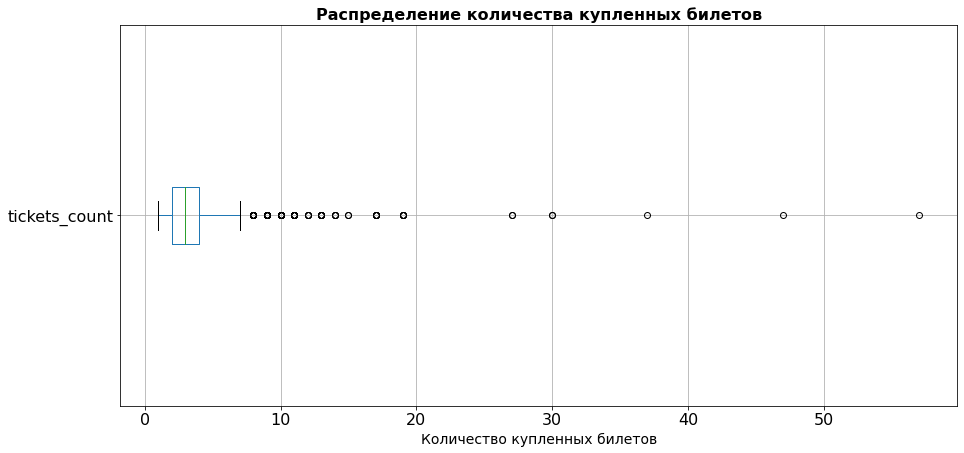

In [20]:
# Строим гистограмму размаха с помощью pandas через boxplot
df.boxplot(
        column=['tickets_count'], # Выбираем столбец tickets_count
        vert=False,       # Делаем график горизонтальным
        fontsize=16,      # Задаем размер шрифта подписей на графике
        figsize=(15, 7),  # Задаем размер графика
    )

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение количества купленных билетов', fontsize=16, weight='bold')
plt.xlabel('Количество купленных билетов', fontsize=14)

# Выводим график
plt.show() 

Гистограмма размаха, тем не менее, показывает, что все значения выше `9` стоит считать выбросами. Однако удалять их точно не стоит - вполне возможно кто-то покупал билеты на компанию.

Перейдем к столбцу `revenue_rub`. Выведем числовые статистики для него с помощью метода `describe()`.

In [21]:
# Выводим числовые статистики для столбца revenue_rub
print(df['revenue_rub'].describe())

count    290611.000000
mean        555.571960
std         875.498169
min         -90.760002
25%         113.970001
50%         351.140015
75%         802.049988
max       81174.539062
Name: revenue_rub, dtype: float64


Статистика здесь уже интереснее. Медиана достаточно сильно отличается от среднего, кроме того - присутствует отрицательное значение прибыли, а максимальное значение составляет порядка `81000`. Построим гистограмму размаха и после решим, что делать с данными.

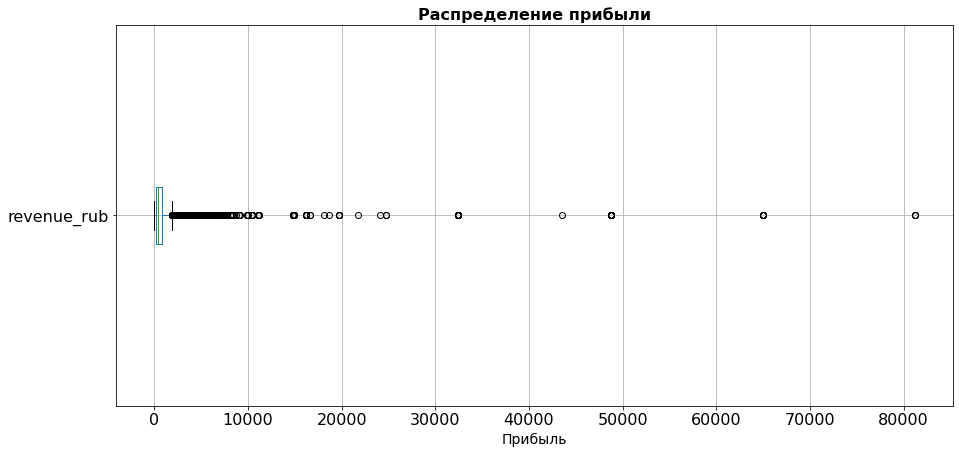

In [22]:
# Строим гистограмму размаха с помощью pandas через boxplot
df.boxplot(
        column=['revenue_rub'], # Выбираем столбец revenue_rub
        vert=False,       # Делаем график горизонтальным
        fontsize=16,      # Задаем размер шрифта подписей на графике
        figsize=(15, 7),  # Задаем размер графика
    )

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение прибыли', fontsize=16, weight='bold')
plt.xlabel('Прибыль', fontsize=14)

# Выводим график
plt.show() 

На гистограмме явно видны сильные выбросы вправо - как минимум `5` значений выше `30000`. Выведем также количество строк с отрицальным и нулевым значениеми прибыли.

In [23]:
# Выводим количество записей с отрицальным значением прибыли
print(len(df[df['revenue_rub'] < 0]))

# Выводим количество записей с нулевым значением прибыли
print(len(df[df['revenue_rub'] == 0]))

381
5526


В данных `381` запись с отрицательным значением прибыли и `5526` с нулевым значением прибыли. Природа таких данных не понятна, поскольку отрицательное значение может означать как возврат билетов, так и ошибку в данных. Нулевое значение может означать отсутствие данных по прибыли. В любом случае - удалять их смысла нет. Отрицательные значения малы по количеству и значению, а значит, влияние на статистику они почти не оказывают - нулевое значение может нести в себе смысл, а значит его удаление тоже неправильно. А вот выбросы в большую сторону стоит исключить - их также достаточно мало, но вот они уже могут оказать большое влияние на статистику (это уже видно по разнице между средним и медианой), поэтому, стоит отфильтровать данные по `99` процентилю.

In [24]:
# Собираем данные по 0.99 процентилю
quantile_99 = df['revenue_rub'].quantile(0.99)

# Сохраняем старый размер выборки
old_shape = df.shape[0]

# Оставляем только строки, ниже 99 процентиля
df = df[df['revenue_rub'] < quantile_99]

print(old_shape)
print(df.shape[0])
print((old_shape - df.shape[0]) / old_shape * 100)

290611
287604
1.0347165110749421


In [25]:
# Выводим новую информацию о датафрейме
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 287604 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                287604 non-null  object        
 1   device_type_canonical  287604 non-null  object        
 2   order_id               287604 non-null  int32         
 3   order_dt               287604 non-null  datetime64[ns]
 4   order_ts               287604 non-null  datetime64[ns]
 5   currency_code          287604 non-null  object        
 6   revenue                287604 non-null  float32       
 7   tickets_count          287604 non-null  int8          
 8   days_since_prev        265892 non-null  Int16         
 9   event_id               287604 non-null  int32         
 10  service_name           287604 non-null  object        
 11  event_name             287604 non-null  object        
 12  event_type_main        287604 non-null  obje

Таким образом, мы оставили все данные ниже 99 процентиля. Суммарно удалилось `1.03%` данных.

Теперь осталось разобраться только с явными дубликатами. Рассчитаем количество полных дубликатов в `df`

In [26]:
# Выводим количество полных дубликатов
print(df.duplicated().sum())

0


<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__

В единственной или последней строке ячейки кода Юпитера, метод print() не обязателен, в отличии от тренажера

Полных дубликатов в данных нет.

Таким образом, в результате предобработки данных мы сделали следующее:
- Добавили новый столбец `revenue_rub`, который содержит данные о прибыле в единой валюте - российском рубле.
- Понизили размерность числовых столбцов.
- Проверили и обработали пропуски.
- Проверили данные на явные и неявные дубликаты. Их не оказалось.
- Посмотрели на числовые статистики для столбцов `tickets_count` и `revenue_rub`. Для `tickets_count` данные оказались нормальными, а в `revenue_rub` обнаружены аномальные значения. Данные в датафрейме были отфильтрованы по `99` процентилю столбца `revenue_rub`. Количество отфильтрованных данных составляет около `1%`.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
    
* В целом с задачей справились, предобработку провели!
    
    
* Хорошо, что сопровождаешь графики заголовком и всеми необходимыми подписями - сразу понятно, что изображено на нем и как его читать!

</div>
<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__

    
* Сейчас ты фиксируешь общие выводы только в конце раздела. Чтобы в работе был понятный сторителлинг, стоит также фиксировать промежуточные свои наблюдения для каждого из шагов: почему мы ничего не стали делать с пропусками и перешли к следующему шагу? Как приняли решение скорректировать тип у тех или иных столбцов? Действительно ли наши категориальные признаки в порядке и не требуют нормализации? Действительно ли в числовых признаках есть выбросы, какова их предполагаемая природа возникновения? Почему мы решили отбросить выбросы в выручке? Почему решили не отбрасывать выбросы в количестве билетов?
    


    
</div>

<a id="3"></a>
## 3. Создание профиля пользователя

**Задача 3.1. Создание профиля пользователя.**


Создадим профиль пользователя для прогнозирования его вовзрата. Для этого создадим новый датасет `profiles_df` со следующими полями:
- Дата первого и последнего заказа;
- Устройство, с которого был сделан первый заказ;
- Регион, в котором был сделан первый заказ;
- Билетного партнёра, к которому обращались при первом заказе;
- Жанр первого посещённого мероприятия;
- Общее количество заказов;
- Средняя выручка с одного заказа в рублях;
- Среднее количество билетов в заказе;
- Среднее время между заказами.

In [27]:
# Отсортируем датафрейм по полю order_ts и с помощью drop_duplicates возьмем только ПЕРВЫЕ значения 
# для каждого из полей user_id, device_type_canonical, region_name, service_name, event_type_main

profiles_df = df.sort_values('order_ts').drop_duplicates(subset='user_id', keep='first')[[
    'user_id', 'device_type_canonical', 'region_name', 'service_name', 'event_type_main']]

# Создадим промежуточный датасет, в котором соберем агрегированную информацию для каждого пользователя
temp_profile_df = df.groupby('user_id').agg(
    first_date=('order_dt', 'min'),                    # Дата первого заказа
    last_date=('order_dt', 'max'),                     # Дата последнего заказа
    total_orders=('order_id', 'count'),                # Общее количество заказов
    mean_revenue=('revenue_rub', 'mean'),              # Средняя выручка одного заказа в рублях
    mean_tickets_count=('tickets_count', 'mean'),      # Среднее количество билетов в заказе
    mean_days_since_prev=('days_since_prev', 'mean'),  # Среднее время между заказами
)

# Соединяем оба датафрейма по полю user_id
profiles_df = profiles_df.merge(temp_profile_df, on='user_id')

# Переименуем столбцы для корректности 
new_names = {
    'device_type_canonical': 'first_device_type_canonical',
    'region_name': 'first_region_name',
    'service_name': 'first_service_name',
    'event_type_main': 'first_event_type_main'
}

# Переименовывем столбцы
profiles_df = profiles_df.rename(columns=new_names)

Теперь добавим 2 бинарных признака:
- `is_two` — совершил ли пользователь 2 и более заказа;
- `is_five` — совершил ли пользователь 5 и более заказов.

In [28]:
# создаем новый столбец is_two на основе total_orders
profiles_df['is_two']  = (profiles_df['total_orders'] >= 2).astype('int8')

# создаем новый столбец is_five на основе total_orders
profiles_df['is_five'] = (profiles_df['total_orders'] >= 5).astype('int8')

In [29]:
# Выводим информацию о датафрейме profiles_df
profiles_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 21848 entries, 0 to 21847
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   user_id                      21848 non-null  object        
 1   first_device_type_canonical  21848 non-null  object        
 2   first_region_name            21848 non-null  object        
 3   first_service_name           21848 non-null  object        
 4   first_event_type_main        21848 non-null  object        
 5   first_date                   21848 non-null  datetime64[ns]
 6   last_date                    21848 non-null  datetime64[ns]
 7   total_orders                 21848 non-null  int64         
 8   mean_revenue                 21848 non-null  float32       
 9   mean_tickets_count           21848 non-null  float64       
 10  mean_days_since_prev         13518 non-null  Float64       
 11  is_two                       21848 non-nu

Таким образом, мы успешно создали профиль пользователя, собрав необходимую информацию в единый датафрейм, а также добавили два новых бинарных признака - `is_two` и `is_five`.

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__
    
* Также есть довольно удобный метод [assign](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.assign.html), позволяющий дополнять таблицу новыми рассчитанными столбцами.
    
    Тогда создание всего профиля можно будет записать красивым и удобным по структуре кодом.

    <details> <summary> <span style='color:blue' > Развернуть подробнее. </span> </summary>

    ```python
    profiles = (df
            # В начале сортируем данные по дате совершения заказа, что найти первые признаки:
            .sort_values(by='order_ts')
            # Затем группируем по номеру пользователя и агрегируем данные:
            .groupby('user_id')
            .agg(
                # Находим первую и последнюю даты заказа:
                first_order_dt=('order_dt','min'),
                last_order_dt=('order_dt','max'),
                # Находим устройства, регион, название билетного партнера и тип мероприятия первого заказа:
                first_device=('device_type_canonical','first'),
                first_region_name=('region_name','first'),
                first_service_name=('service_name','first'),
                first_event_type=('event_type_main','first'),
                # Подсчитваем количество заказов:
                total_orders=('order_id','nunique'),
                # Считаем статистику по заказам: средняя стоимость заказа, среднее количество билетов:
                avg_revenue_rub=('revenue_rub','mean'),
                avg_tickets_count=('tickets_count','mean'),
                # Считаем среднее количество дней между покупками:
                avg_days_since_prev=('days_since_prev','mean')
            )
            # Создаем два признака: совершил ли пользователь 2 / 5 и более заказов:
            .assign(
                is_two = lambda x: x['total_orders'] >= 2,
                is_five = lambda x: x['total_orders'] >= 5
            )
            .reset_index()
    )
    ```
    </details>

    

    
</div>


**Задача 3.2. Общий анализ профиля пользователей.**


Рассчитаем следующие характеристики на основе датафрейма `profiles_df`:

- Общее число пользователей в выборке;
- Среднюю выручку с одного заказа;
- Долю пользователей, совершивших 2 и более заказа;
- Долю пользователей, совершивших 5 и более заказов.

Сделаем это с помощью кода ниже.

In [30]:
# Выводим общее число пользователей в выборке
print(len(profiles_df['user_id'].unique()))
print()

# Выводим среднюю выручку с одного заказа
print(round(profiles_df['mean_revenue'].mean(), 2))
print()

# Выводим долю пользователей, совершивших 2 и более заказа
print(round(profiles_df['is_two'].mean(), 3))
print()

# Выводим долю пользователей, совершивших 5 и более заказов
print(round(profiles_df['is_five'].mean(), 3))

21848

543.39

0.617

0.29


Получаем следующие результаты:
- В данных содержится информация о `21848` пользователях.
- Средняя выручка с одного заказа - `543.39` рублей.
- Доля пользователей, совершивших 2 и более заказа - `0.617`.
- доля пользователей, совершивших 5 и более заказов - `0.29`.

Теперь изучим статистические показатели по общему числу заказов.

In [31]:
# Выводим числовые статистики для столбца total_orders
print(profiles_df['total_orders'].describe())

count    21848.000000
mean        13.163859
std        121.624128
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max      10175.000000
Name: total_orders, dtype: float64


В данных присутствуют явные аномалии - кто-то совершил `10175` заказов. Выглядит как явная ошибка, хотя возможно - это перекупщики билетов. В любом случае, среднее существенно выше медианы, а `50%` и `75%` процентили корректны и соотносятся с данные о пользователях, совершивших `2+` и `5+` заказов, рассчитанных выше. Построим гистограмму размаха для наглядности.

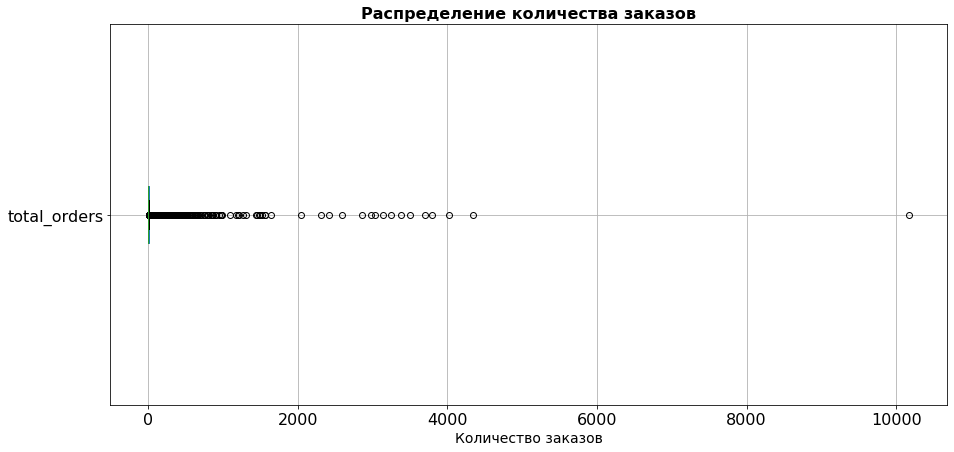

In [32]:
# Строим гистограмму размаха с помощью pandas через boxplot
profiles_df.boxplot(
        column=['total_orders'], # Выбираем столбец total_orders
        vert=False,              # Делаем график горизонтальным
        fontsize=16,             # Задаем размер шрифта подписей на графике
        figsize=(15, 7),         # Задаем размер графика
    )

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение количества заказов', fontsize=16, weight='bold')
plt.xlabel('Количество заказов', fontsize=14)

# Выводим график
plt.show() 

Диаграмма размаха существенно смещена вправо, попробуем отфильтровать данные по `99` процентилю и повторить проверку.

In [33]:
# Собираем данные по 0.99 процентилю
quantile_99 = profiles_df['total_orders'].quantile(0.99)

# Сохраняем старый размер выборки
old_shape = profiles_df.shape[0]

# Оставляем только строки, ниже 99 процентиля
profiles_df = profiles_df[profiles_df['total_orders'] < quantile_99]

print(old_shape)
print(profiles_df.shape[0])
print((old_shape - profiles_df.shape[0]) / old_shape * 100)

21848
21628
1.0069571585499817


Отфильтрован `1%` данных. Построим гистограмму размаха еще раз.

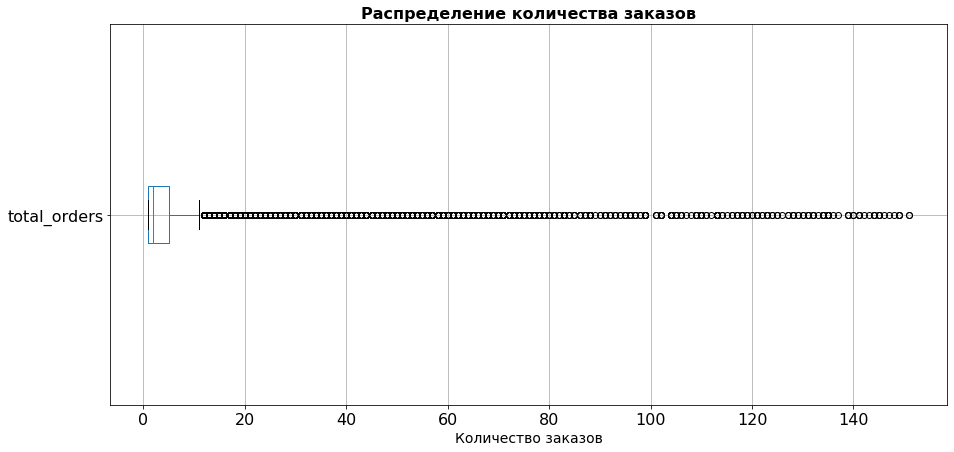

In [34]:
# Строим гистограмму размаха с помощью pandas через boxplot
profiles_df.boxplot(
        column=['total_orders'], # Выбираем столбец total_orders
        vert=False,              # Делаем график горизонтальным
        fontsize=16,             # Задаем размер шрифта подписей на графике
        figsize=(15, 7),         # Задаем размер графика
    )

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение количества заказов', fontsize=16, weight='bold')
plt.xlabel('Количество заказов', fontsize=14)

# Выводим график
plt.show() 

Гистограмма теперь выглядит корректнее, хотя все еще указывает, что количество заказов выше примерно `12` можно считать выбросами. Тем не менее, аномальные значения удалены.

Теперь изучим статистические показатели по среднему числу билетов в заказе.

In [35]:
# Выводим числовые статистики для столбца mean_tickets_count
print(profiles_df['mean_tickets_count'].describe())

count    21628.000000
mean         2.743110
std          0.917881
min          1.000000
25%          2.000000
50%          2.750000
75%          3.100000
max         11.000000
Name: mean_tickets_count, dtype: float64


Здесь ситуация существенно лучше. Медиана почти равна среднему, а максимальное значение `11` выглядит вполне корректным - кто-то покупал билеты на компанию. Возможно сыграл роль тот факт, что мы отфильтровали данные по `total_orders`. Построим гистограмму размаха для наглядности.

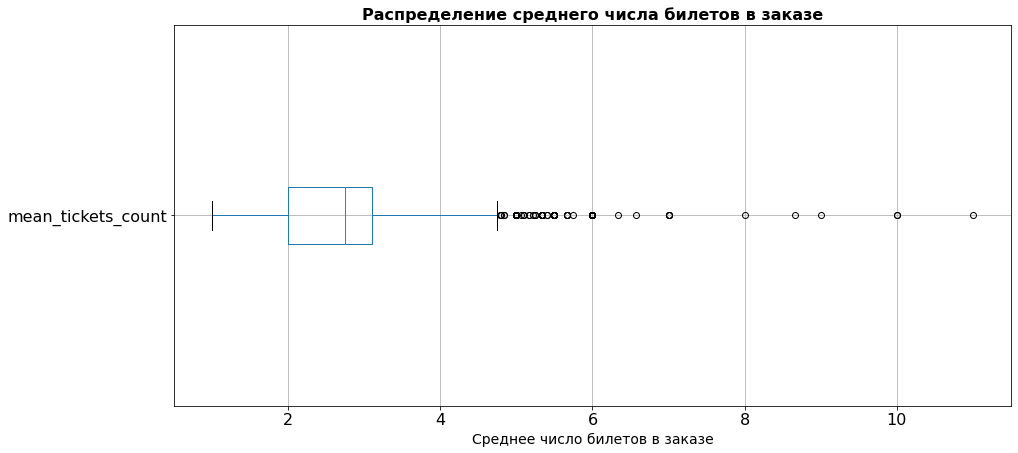

In [36]:
# Строим гистограмму размаха с помощью pandas через boxplot
profiles_df.boxplot(
        column=['mean_tickets_count'], # Выбираем столбец mean_tickets_count
        vert=False,                    # Делаем график горизонтальным
        fontsize=16,                   # Задаем размер шрифта подписей на графике
        figsize=(15, 7),               # Задаем размер графика
    )

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение среднего числа билетов в заказе', fontsize=16, weight='bold')
plt.xlabel('Среднее число билетов в заказе', fontsize=14)

# Выводим график
plt.show() 

Гистограмма подтверждает вывод выше - данные вполне корректны. Значения выше `5` вряд ли могут считаться выбросами.

Наконец, изучим статистику по среднему количеству дней между покупками.

In [37]:
# Выводим числовые статистики для столбца mean_tickets_count
print(profiles_df['mean_days_since_prev'].describe())

count    13298.000000
mean        16.103007
std         22.410140
min          0.000000
25%          1.333333
50%          8.369318
75%         20.750000
max        148.000000
Name: mean_days_since_prev, dtype: float64


Здесь данные тоже выглядят корректными. Хотя медиана и отличается от среднего почти в 2 раза, кто-то действительно мог не совершать повторный заказ достаточно долго. Построим гистограмму размаха.

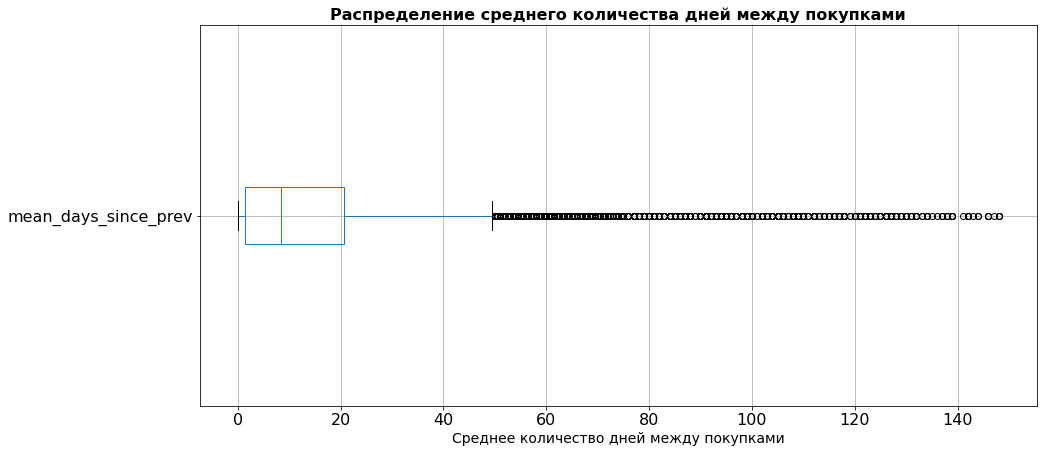

In [38]:
# Строим гистограмму размаха с помощью pandas через boxplot
profiles_df.boxplot(
        column=['mean_days_since_prev'], # Выбираем столбец mean_days_since_prev
        vert=False,                      # Делаем график горизонтальным
        fontsize=16,                     # Задаем размер шрифта подписей на графике
        figsize=(15, 7),                 # Задаем размер графика
    )

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение среднего количества дней между покупками', fontsize=16, weight='bold')
plt.xlabel('Среднее количество дней между покупками', fontsize=14)

# Выводим график
plt.show() 

Диаграмма размаха выглядит корректно. И хотя она показывает, что значения выше `50` можно считать выбросами - это не совсем так. Пользователи явно могли совершать заказы раз в несколько месяцев. Эти значения полезны при анализе.

In [39]:
# Выводим общую информацию о датасете
profiles_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 21628 entries, 1 to 21847
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   user_id                      21628 non-null  object        
 1   first_device_type_canonical  21628 non-null  object        
 2   first_region_name            21628 non-null  object        
 3   first_service_name           21628 non-null  object        
 4   first_event_type_main        21628 non-null  object        
 5   first_date                   21628 non-null  datetime64[ns]
 6   last_date                    21628 non-null  datetime64[ns]
 7   total_orders                 21628 non-null  int64         
 8   mean_revenue                 21628 non-null  float32       
 9   mean_tickets_count           21628 non-null  float64       
 10  mean_days_since_prev         13298 non-null  Float64       
 11  is_two                       21628 non-nu

Выведем общую информацию после филтрации.

In [40]:
# Выводим общее число пользователей в выборке
print(len(profiles_df['user_id'].unique()))
print()

# Выводим среднюю выручку с одного заказа
print(round(profiles_df['mean_revenue'].mean(), 2))
print()

# Выводим долю пользователей, совершивших 2 и более заказа
print(round(profiles_df['is_two'].mean(), 3))
print()

# Выводим долю пользователей, совершивших 5 и более заказов
print(round(profiles_df['is_five'].mean(), 3))

21628

543.69

0.613

0.283


Таким образом, в результате оценки статистических показателей можно сделать следующие выводы:
- Общее количество заказов имело аномальное значение для некоторых пользователей, в результате чего было принято решение отфильтровать их по `99` процентилю. В результате был удален `1%` данных.
- После фильтрации имеем `21628` уникальных пользователей.
- Среднее число билетов в заказе и среднее количество дней между покупками статистически корректны и вполне реальны.
- Представленные данные достаточны по объему и на их основе можно проводить исследования.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

    
Здесь  все супер, выполнены все необходимые шаги! 
    
    
Как рекомендация, было бы не лишним также проверить, насколько изменилась средняя выручка после удаления выбросов. Посмотреть на распределение данных с помощью гистограмм и диаграмм размаха.    
    
    
Так же, хорошо было бы лучше сначала обосновать выбор стратегии по обработке, а потом уже приступить к ее выполнению при необходимости.    

<a id="4"></a>
## 4. Исследовательский анализ данных

Займемся исследовательским анализом данных на основе сформированного профиля пользователей.



#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

Исследуем признаки, описывающие первый заказ пользователя, и попытаемся выяснить, влияют ли они на вероятность возвращения пользователя.


**Задача 4.1.1. Распределение пользователей по признакам.**


Посчитаем количество пользователей и их долю в разрезе типа их первого мероприятия.

In [41]:
# Абсолютное количество пользователей в разрезе типа их первого мероприятия
print(profiles_df['first_event_type_main'].value_counts())
print()

# Относительное количество пользователей в разрезе типа их первого мероприятия
print(profiles_df['first_event_type_main'].value_counts(normalize=True))

концерты    9549
другое      5427
театр       4239
стендап     1110
спорт        794
выставки     414
ёлки          95
Name: first_event_type_main, dtype: int64

концерты    0.441511
другое      0.250925
театр       0.195996
стендап     0.051322
спорт       0.036712
выставки    0.019142
ёлки        0.004392
Name: first_event_type_main, dtype: float64


Построим круговую диаграмму для наглядности.

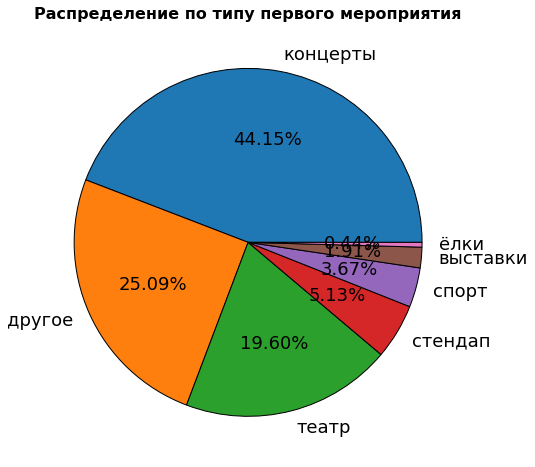

In [42]:
# Строим гистограмму размаха с помощью pandas через .plot.pie
profiles_df['first_event_type_main'].value_counts().plot.pie(
    y='count',                        # Задаем имя колонки для расчетов
    autopct='%1.2f%%',                # Задаем формат подписи долей
    fontsize=18,                      # Задаем размер шрифта подписей на графике
    figsize=(16, 8),                  # Задаем размер графика
    ylabel='',                        # Убираем подпись оси Y
    wedgeprops={'edgecolor': 'black', # Задаем цвет границы
                'linewidth': 1}       # Задаем толщину границы
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение по типу первого мероприятия', fontsize=16, weight='bold')

# Выводим график
plt.show()

Данные явно распределены неравнемерно. Лидируют концерты с `44%`, а ёлки составляют лишь `0.44%`.

Посчитаем количество пользователей и их долю в разрезе типа устройства, с которого был совершен первый заказ.

In [43]:
# Абсолютное количество пользователей в разрезе региона проведения мероприятия из первого заказа
print(profiles_df['first_device_type_canonical'].value_counts())
print()

# Относительное количество пользователей в разрезе региона проведения мероприятия из первого заказа
print(profiles_df['first_device_type_canonical'].value_counts(normalize=True))

mobile     17919
desktop     3709
Name: first_device_type_canonical, dtype: int64

mobile     0.828509
desktop    0.171491
Name: first_device_type_canonical, dtype: float64


Построим круговую диаграмму для наглядности.

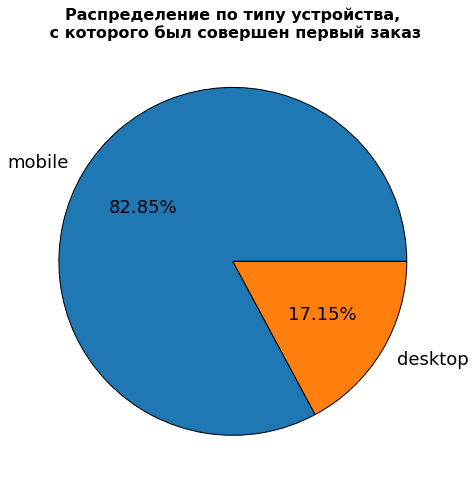

In [44]:
# Строим гистограмму размаха с помощью pandas через .plot.pie
profiles_df['first_device_type_canonical'].value_counts().plot.pie(
    y='count',                        # Задаем имя колонки для расчетов
    autopct='%1.2f%%',                # Задаем формат подписи долей
    fontsize=18,                      # Задаем размер шрифта подписей на графике
    figsize=(16, 8),                  # Задаем размер графика
    ylabel='',                        # Убираем подпись оси Y
    wedgeprops={'edgecolor': 'black', # Задаем цвет границы
                'linewidth': 1}       # Задаем толщину границы
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение по типу устройства,\n с которого был совершен первый заказ', fontsize=16, weight='bold')

# Выводим график
plt.show()

Здесь данные также распределены неравномерно - на мобильные телефоны приходится почти `83%` всех первых заказов.

Посчитаем количество пользователей и их долю в разрезе региона проведения мероприятия из первого заказа.

In [45]:
# Абсолютное количество пользователей в разрезе региона проведения мероприятия из первого заказа
print(profiles_df['first_region_name'].value_counts())
print()

# Относительное количество пользователей разрезе региона проведения мероприятия из первого заказа
print(profiles_df['first_region_name'].value_counts(normalize=True))

Каменевский регион          7086
Североярская область        3767
Широковская область         1224
Озернинский край             675
Малиновоярский округ         525
                            ... 
Залесский край                 2
Тихогорская область            2
Верхозёрский край              1
Яснопольский округ             1
Сосноводолинская область       1
Name: first_region_name, Length: 81, dtype: int64

Каменевский регион          0.327631
Североярская область        0.174172
Широковская область         0.056593
Озернинский край            0.031210
Малиновоярский округ        0.024274
                              ...   
Залесский край              0.000092
Тихогорская область         0.000092
Верхозёрский край           0.000046
Яснопольский округ          0.000046
Сосноводолинская область    0.000046
Name: first_region_name, Length: 81, dtype: float64


Здесь регионов уже слишком много, возьмем первые `10` регионов, а остальные определим в категорию `Другой`.

In [46]:
# Абсолютное количество пользователей в разрезе региона проведения мероприятия из первого заказа
profiles_df_by_first_region = profiles_df['first_region_name'].value_counts()

# Берём 10 самых популярных регионов
top_10_regions = profiles_df_by_first_region.head(10)

# Суммируем всё остальное в "Другой"
other_regions_sum = profiles_df_by_first_region[10:].sum()
top_10_regions['Другой'] = other_regions_sum

# Выводим новое распределение
print(top_10_regions)

Каменевский регион      7086
Североярская область    3767
Широковская область     1224
Озернинский край         675
Малиновоярский округ     525
Шанырский регион         500
Травяная область         488
Светополянский округ     457
Речиновская область      440
Яблоневская область      411
Другой                  6055
Name: first_region_name, dtype: int64


Построим круговую диаграмму для наглядности.

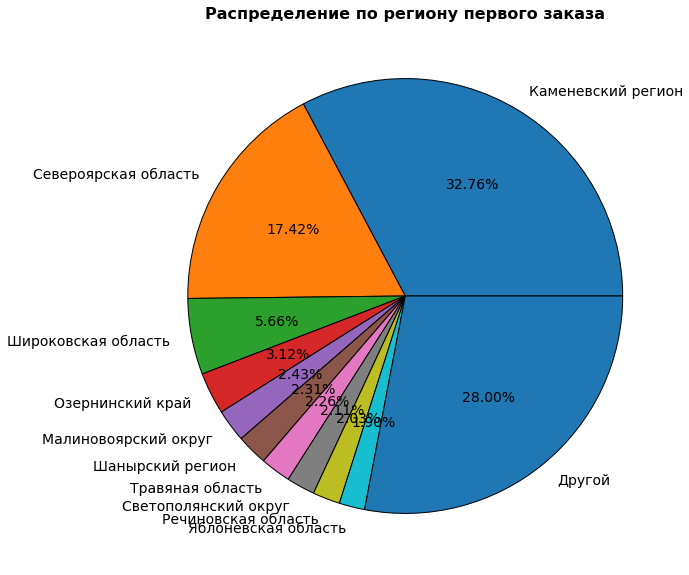

In [47]:
# Строим гистограмму размаха с помощью pandas через .plot.pie
top_10_regions.plot.pie(
    y='count',                        # Задаем имя колонки для расчетов
    autopct='%1.2f%%',                # Задаем формат подписи долей
    fontsize=14,                      # Задаем размер шрифта подписей на графике
    figsize=(20, 10),                 # Задаем размер графика
    ylabel='',                        # Убираем подпись оси Y
    wedgeprops={'edgecolor': 'black', # Задаем цвет границы
                'linewidth': 1}       # Задаем толщину границы
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение по региону первого заказа', fontsize=16, weight='bold')

# Выводим график
plt.show()

Данные также распределены неравномерно. Лидирует `Каменевский регион` с `33%` всех заказов, большинство регионов имеют данные ниже `2%`, а суммарная доля для `71` региона, не входящих в топ-10 составляет лишь `28%`, то есть даже меньше одного только `Каменевского региона`.

Наконец, посчитаем количество пользователей и их долю в разрезе билетного оператора первого заказа.

In [48]:
# Абсолютное количество пользователей в разрезе билетного оператора первого заказа
print(profiles_df['first_service_name'].value_counts())
print()

# Относительное количество пользователей разрезе билетного оператора первого заказа
print(profiles_df['first_service_name'].value_counts(normalize=True))

Билеты без проблем        5184
Мой билет                 2958
Лови билет!               2810
Билеты в руки             2559
Облачко                   2179
Весь в билетах            1285
Лучшие билеты             1184
Прачечная                  582
Край билетов               454
Дом культуры               356
Яблоко                     318
Тебе билет!                308
Городской дом культуры     215
Мир касс                   209
За билетом!                201
Быстробилет                162
Show_ticket                158
Выступления.ру              95
Восьмёрка                   85
Быстрый кассир              61
Crazy ticket!               45
Росбилет                    40
Радио ticket                36
Реестр                      33
Телебилет                   27
Цвет и билет                22
Шоу начинается!             19
КарандашРУ                  15
Кино билет                   9
Вперёд!                      7
Билет по телефону            6
Тех билет                    3
Лимоны  

Операторов тоже достаточно много. Поступим так же, как и с регионами. Возьмем первые `10` операторов, а остальных определим в категорию `Другой`.

In [49]:
# Абсолютное количество пользователей в разрезе билетного оператора первого заказа
profiles_df_by_first_service_name = profiles_df['first_service_name'].value_counts()

# Берём 10 самых популярных операторов
top_10_service_names = profiles_df_by_first_service_name.head(10)

# Суммируем всё остальное в «Другой»
other_services_sum = profiles_df_by_first_service_name[10:].sum()
top_10_service_names['Другой'] = other_services_sum

# Выводим новое распределение
print(top_10_service_names)

Билеты без проблем    5184
Мой билет             2958
Лови билет!           2810
Билеты в руки         2559
Облачко               2179
Весь в билетах        1285
Лучшие билеты         1184
Прачечная              582
Край билетов           454
Дом культуры           356
Другой                2077
Name: first_service_name, dtype: int64


Построим круговую диаграмму для наглядности.

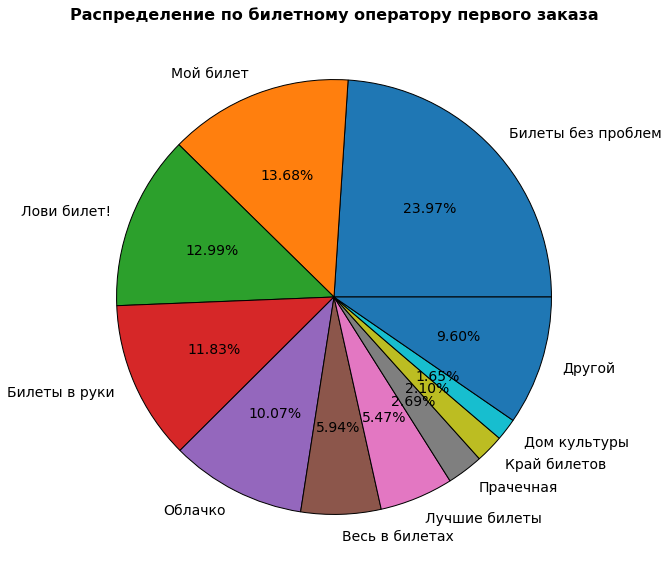

In [50]:
# Строим гистограмму размаха с помощью pandas через .plot.pie
top_10_service_names.plot.pie(
    y='count',                        # Задаем имя колонки для расчетов
    autopct='%1.2f%%',                # Задаем формат подписи долей
    fontsize=14,                      # Задаем размер шрифта подписей на графике
    figsize=(20, 10),                 # Задаем размер графика
    ylabel='',                        # Убираем подпись оси Y
    wedgeprops={'edgecolor': 'black', # Задаем цвет границы
                'linewidth': 1}       # Задаем толщину границы
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение по билетному оператору первого заказа', fontsize=16, weight='bold')

# Выводим график
plt.show()

Данные также распределены неравномерно. Лидирует оператор `Билеты без проблем` с `24%`. На всех остальных операторов, не входящих в топ-10, приходится лишь `9.6%`.

Таким образом, все данные распределены неравномерно. Есть явные лидеры в каждом сегменты.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

По результатам всё верно
    
    
<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__
    
* Можно создать пользовательскую функцию, чтобы не прописывать практически один и тот же код несколько раз  
    
        def segment_summary(df, column):
        seg = (df.groupby(column).agg(users_count=('user_id', 'nunique')) .reset_index().sort_values('users_count', ascending=False))
        seg['users_share'] = (seg['users_count'] / seg['users_count'].sum() *100)
        seg['users_share'] = seg['users_share'].round(2)
        return seg


* По выводам хорошо бы показать общую картину: как распределяются пользователи по сегментам, какие группы преобладают, какие встречаются реже и почему так может быть. А уже после этого привести конкретные значения - как подтверждение своих наблюдений.  


**Задача 4.1.2. Анализ возвратов пользователей.**



Вычислим долю пользователей, совершивших два и более заказа для каждого сегмента, выделенного в прошлой задаче. Начнем с типа устройства, с которого был совершен первый заказ.

In [51]:
# Группируем пользователей по типу устройства, с которого был совершен первый заказ
grouped_first_device_type_canonical = profiles_df.groupby('first_device_type_canonical')['is_two'].agg(
    count='count',        # Сколько пользователей в каждом сегменте
    count_is_two='sum',   # Cколько пользователей имеют 2 и более заказа
    share_is_two='mean'   # Доля пользователей, имеющих 2 и более заказа
).sort_values(by='share_is_two', ascending=False)
grouped_first_device_type_canonical

,count,count_is_two,share_is_two
first_device_type_canonical,,,
desktop,3709,2368.0,0.638447
mobile,17919,10895.0,0.608014


Визуализируем данные на столбчатой диаграмме, отобразив при этом и общий процент пользователей, совершивших 2 и более заказа.

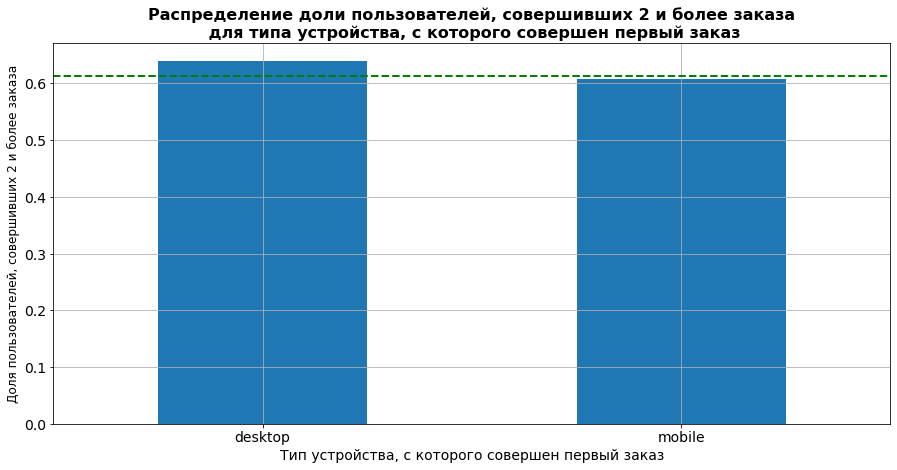

In [52]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
grouped_first_device_type_canonical['share_is_two'].plot(
           kind='bar',     # Тип графика - столбчатая диаграмма
           rot=0,          # Градус вращения подписи по оси Х
           fontsize=14,    # Устанавливаем размер шрифта
           legend=False,   # Выключаем легенду
           figsize=(15, 7) # Задаем размер графика
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение доли пользователей, совершивших 2 и более заказа\n для типа устройства, с которого совершен первый заказ', fontsize=16, weight='bold')
plt.xlabel('Тип устройства, с которого совершен первый заказ', fontsize=14)
plt.ylabel('Доля пользователей, совершивших 2 и более заказа', fontsize=12)

# Рассчитываем долю пользователей, совершивших 2 и более заказа
is_two_share = profiles_df['is_two'].mean()

# Наносим на график линию с долей пользователей, совершивших 2 и более заказа
plt.axhline(is_two_share,   # Данные, по которым строится линия
            color='green',  # Цвет линии
            linestyle='--', # Стиль линии
            linewidth=2     # Ширина линии
)

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show() 

По графику и данным видно, что доля пользователей, совершивших 2 и более заказа для типа устройства `desktop` выше, чем для `mobile` - `0.638%` против `0.608%`.

Теперь вычислим долю пользователей, совершивших 2 и более заказа для типа первого мероприятия.

In [53]:
# Группируем пользователей по типу первого мероприятия
grouped_first_event_type_main = profiles_df.groupby('first_event_type_main')['is_two'].agg(
    count='count',        # Сколько пользователей в каждом сегменте
    count_is_two='sum',   # Cколько пользователей имеют 2 и более заказа
    share_is_two='mean'   # Доля пользователей, имеющих 2 и более заказа
).sort_values(by='share_is_two', ascending=False)
grouped_first_event_type_main

,count,count_is_two,share_is_two
first_event_type_main,,,
выставки,414,265.0,0.640097
театр,4239,2687.0,0.633876
концерты,9549,5903.0,0.618180
стендап,1110,676.0,0.609009
другое,5427,3236.0,0.596278
спорт,794,443.0,0.557935
ёлки,95,53.0,0.557895


Визуализируем данные на столбчатой диаграмме, отобразив при этом и общий процент пользователей, совершивших 2 и более заказа.

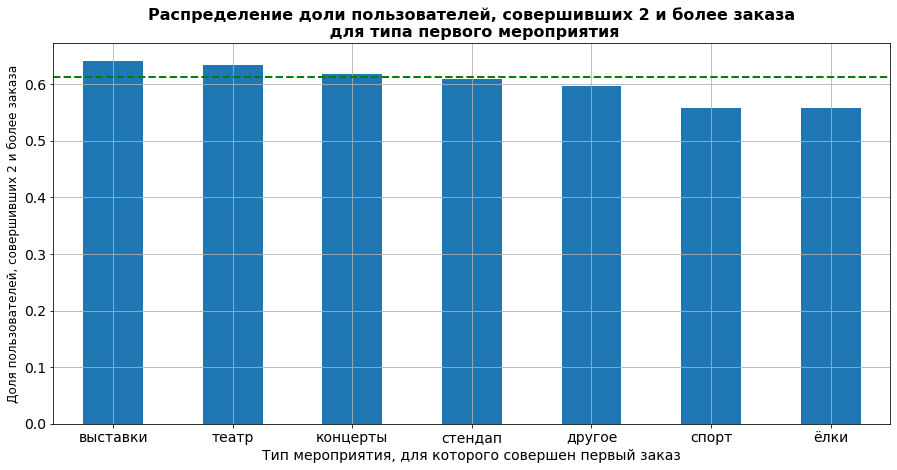

In [54]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
grouped_first_event_type_main['share_is_two'].plot(
           kind='bar',     # Тип графика - столбчатая диаграмма
           rot=0,          # Градус вращения подписи по оси Х
           fontsize=14,    # Устанавливаем размер шрифта
           legend=False,   # Выключаем легенду
           figsize=(15, 7) # Задаем размер графика
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение доли пользователей, совершивших 2 и более заказа\n для типа первого мероприятия', fontsize=16, weight='bold')
plt.xlabel('Тип мероприятия, для которого совершен первый заказ', fontsize=14)
plt.ylabel('Доля пользователей, совершивших 2 и более заказа', fontsize=12)

# Рассчитываем долю пользователей, совершивших 2 и более заказа
is_two_share = profiles_df['is_two'].mean()

# Наносим на график линию с долей пользователей, совершивших 2 и более заказа
plt.axhline(is_two_share,   # Данные, по которым строится линия
            color='green',  # Цвет линии
            linestyle='--', # Стиль линии
            linewidth=2     # Ширина линии
)

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show() 

По графику и данным видно, что доля пользователей, совершивших 2 и более заказа для типа мероприятия распределены неравномерно. Для `выставок` и `театра` они выше, чем в среднем, а для `спорта` и `ёлки` достаточно существенно ниже среднего.

Вычислим долю пользователей, совершивших 2 и более заказа для билетного оператора первого заказа. Поскольку операторов достаточно много, возьмем первые 10 по количеству заказов.

In [55]:
# Группируем пользователей по билетному оператору первого заказа, с помощью сортировки по количеству выбираем топ-10
# билетных операторов и уже сам топ-10 сортируем по доли пользователей, совершивших 2 и более заказа
grouped_first_service_name = profiles_df.groupby('first_service_name')['is_two'].agg(
    count='count',        # Сколько всего пользователей для каждого билетного оператора
    count_is_two='sum',   # Cколько пользователей имеют 2 и более заказа
    share_is_two='mean'   # Доля пользователей, имеющих 2 и более заказа
).sort_values(by='count', ascending=False).head(10).sort_values(by='share_is_two', ascending=False)
grouped_first_service_name

,count,count_is_two,share_is_two
first_service_name,,,
Край билетов,454,296.0,0.651982
Дом культуры,356,230.0,0.646067
Весь в билетах,1285,808.0,0.628794
Билеты в руки,2559,1605.0,0.627198
Прачечная,582,364.0,0.625430
Облачко,2179,1336.0,0.613125
Лучшие билеты,1184,725.0,0.612331
Лови билет!,2810,1712.0,0.609253
Мой билет,2958,1799.0,0.608181


Визуализируем данные на столбчатой диаграмме, отобразив при этом и общий процент пользователей, совершивших 2 и более заказа.

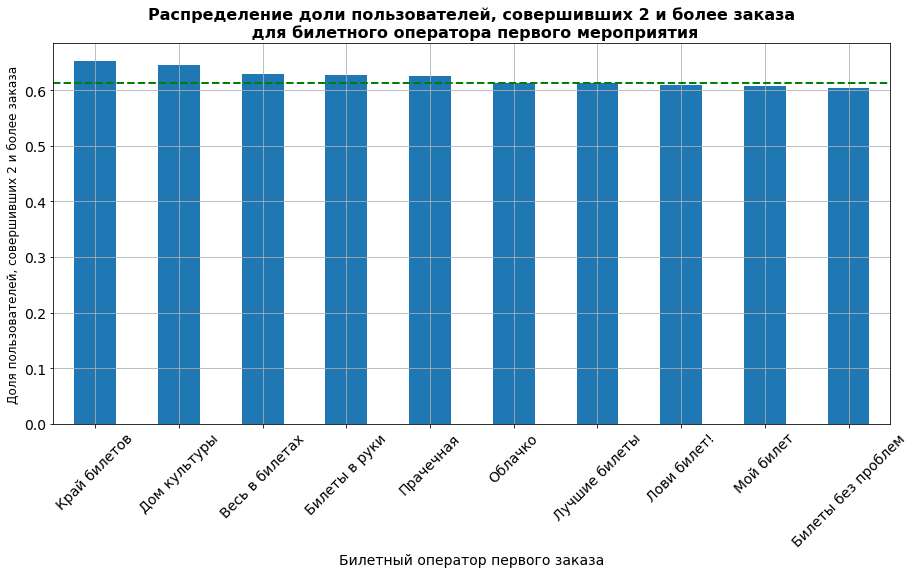

In [56]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
grouped_first_service_name['share_is_two'].plot(
           kind='bar',     # Тип графика - столбчатая диаграмма
           rot=45,         # Градус вращения подписи по оси Х
           fontsize=14,    # Устанавливаем размер шрифта
           legend=False,   # Выключаем легенду
           figsize=(15, 7) # Задаем размер графика
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение доли пользователей, совершивших 2 и более заказа\n для билетного оператора первого мероприятия', fontsize=16, weight='bold')
plt.xlabel('Билетный оператор первого заказа', fontsize=14)
plt.ylabel('Доля пользователей, совершивших 2 и более заказа', fontsize=12)

# Рассчитываем долю пользователей, совершивших 2 и более заказа
is_two_share = profiles_df['is_two'].mean()

# Наносим на график линию с долей пользователей, совершивших 2 и более заказа
plt.axhline(is_two_share,   # Данные, по которым строится линия
            color='green',  # Цвет линии
            linestyle='--', # Стиль линии
            linewidth=2     # Ширина линии
)

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show() 

Здесь данные распределены уже чуть более равномерно. `Край билетов` с `65.2%` и `Дом культуры` с `64.6%` выделяются на фоне остальных заказов, хотя они имеют соответственно `454` и `365` первых заказов, что ниже, чем у остальных операторов, у которых, в большинстве своем, по несколько тысяч первых заказов.

Наконец, вычислим долю пользователей, совершивших 2 и более заказа для региона первого заказа. Различных регионов много, поэтому также возьмем первые 10 по количеству заказов.

In [57]:
# Группируем пользователей по регоину первого заказа, с помощью сортировки по количеству выбираем топ-10 регоинов
# и уже сам топ-10 сортируем по доли пользователей, совершивших 2 и более заказа
grouped_first_region_name = profiles_df.groupby('first_region_name')['is_two'].agg(
    count='count',        # Сколько всего пользователей для каждого регоина
    count_is_two='sum',   # Cколько пользователей имеют 2 и более заказа
    share_is_two='mean'   # Доля пользователей, имеющих 2 и более заказа
).sort_values(by='count', ascending=False).head(10).sort_values(by='share_is_two', ascending=False)
grouped_first_region_name

,count,count_is_two,share_is_two
first_region_name,,,
Шанырский регион,500,336.0,0.672000
Светополянский округ,457,300.0,0.656455
Широковская область,1224,790.0,0.645425
Североярская область,3767,2404.0,0.638174
Речиновская область,440,279.0,0.634091
Каменевский регион,7086,4422.0,0.624047
Травяная область,488,300.0,0.614754
Яблоневская область,411,244.0,0.593674
Малиновоярский округ,525,294.0,0.560000


Визуализируем данные на столбчатой диаграмме, отобразив при этом и общий процент пользователей, совершивших 2 и более заказа.

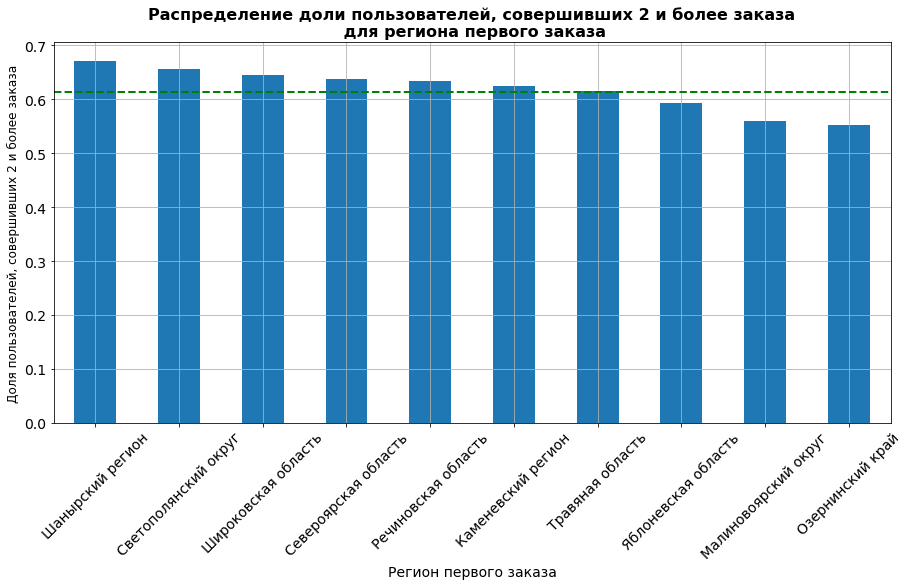

In [58]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
grouped_first_region_name['share_is_two'].plot(
           kind='bar',     # Тип графика - столбчатая диаграмма
           rot=45,         # Градус вращения подписи по оси Х
           fontsize=14,    # Устанавливаем размер шрифта
           legend=False,   # Выключаем легенду
           figsize=(15, 7) # Задаем размер графика
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение доли пользователей, совершивших 2 и более заказа\n для региона первого заказа', fontsize=16, weight='bold')
plt.xlabel('Регион первого заказа', fontsize=14)
plt.ylabel('Доля пользователей, совершивших 2 и более заказа', fontsize=12)

# Рассчитываем долю пользователей, совершивших 2 и более заказа
is_two_share = profiles_df['is_two'].mean()

# Наносим на график линию с долей пользователей, совершивших 2 и более заказа
plt.axhline(is_two_share,   # Данные, по которым строится линия
            color='green',  # Цвет линии
            linestyle='--', # Стиль линии
            linewidth=2     # Ширина линии
)

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show() 

По графику и данным видно, что пользователи, совершившие 2 и более заказа по регионам первого заказа распределены неравномерно. Явным лидером является `Шанырский регион` с `67.2%`, а закрывает топ-10 `Озернинский край` с уже лишь `55.2%`. При это лидирующий `Шанырский регион` имеет `500` первых заказов суммарно.

На основе графиков и данных выше можно сделать вывод, что данные по пользователям, совершившим 2 и более заказа распределены не совсем равномерно. Для каждого сегмента есть явные лидеры. Так, пользователи чаще совершаются заказ с `desktop`, и если первый тип мероприятия `выставки`, при билетном операторе `Край билетов` первого заказа, а также в `Шанырском регионе`.


**Задача 4.1.3. Проверка продуктовых гипотез.**


Проверим следующие гипотезы на основе данных выше:
- **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

**Гипотеза 1** не подверждается. Тип мероприятия действительно оказывает влияние на возврат пользователей, но для `спорта` она составляет `0.558%`, а для `концертов` `0.618%`, то есть наоборот - пользователи, оформившие свой первый заказ на концерты совершают повторный заказ чаще, чем пользователи, которые совершили первый заказ на спортивные мероприятия.

**Гипотеза 2** также не подвержается. Лидер по повторным заказам `Шанырский регион` c `67.2%` возвратов имеет суммарно `500` первых заказов, а, например, `Каменевский регион` c `7086` первых заказов имеет `62.4%`. Из таблицы `grouped_first_region_name` также видно, что большинство топовых регионов по возвратам пользователей имеют в среднем `400-700` заказов.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
    

* По выводам относительно гипотез все верно подмечено! Можно было бы еще сделать более яркий акцент на том, что в топ по повторным заказам вырвались регионы с ощутимо меньшим числом пользователей, а значит оценка показателя возвращаемости у них более чувствительна к колебаниям в количестве пользователей (1 дополнительный пользователь может существеннее повлиять на показатель, как в плюс, так и в минус).

</div>
<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__

* Опять же, было бы не лишним дать понятное название подразделу и добавить пояснение к шагу.
    


</div>

---

#### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа


**Задача 4.2.1. Исследование связи между средней выручкой сервиса с заказа и повторными заказами.**

Построим сравнительные гистограммы распределения средней выручки билета для пользователей совершивших 1 заказ и для пользователей, совершивших 2 и более заказа. Для наглядности поместим их на одном графике и зададим параметру `density` значение `True`, чтобы сравнивать форму распределений, даже если число пользователей в группах отличается, то есть ось `Y` в данном случае будет показывает плотность вероятности, а не частоту.

Количество интервалов `bins` определим в диапазоне от `0` (не будем учитвать отрицательные значения) до максимального значения средней выручки. Возьмем шаг `25` для большей наглядности.

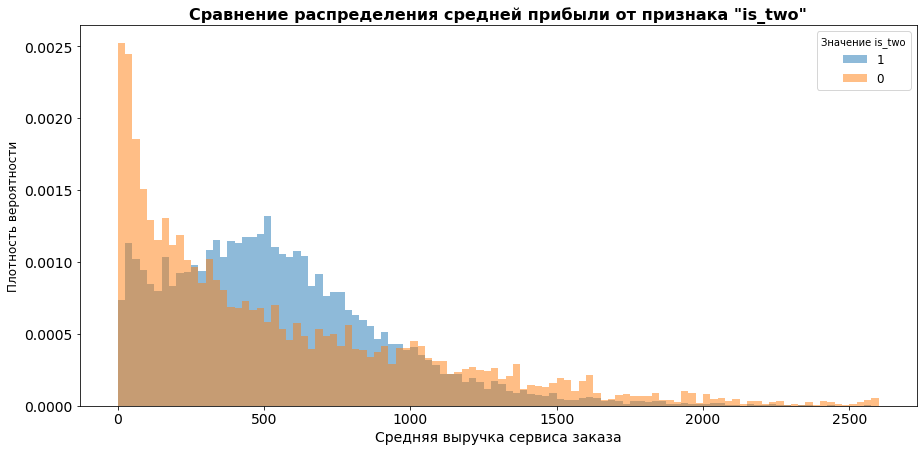

In [59]:
# Строим гистограммы для каждого значения is_two
for i in profiles_df['is_two'].unique():
    # Фильтруем данные по значению столбца is_two
    profiles_df.loc[profiles_df['is_two'] == i, 'mean_revenue'].plot(
        kind='hist',                                               # Тип графика - гистограмма распределения
        density=True,                                              # Задаем значение density как True
        bins=range(0, int(profiles_df['mean_revenue'].max()), 25), # Задаем количество интервалов
        alpha=0.5,                                                 # Задаем прозрачность alpha
        label=f'{i}',                                              # Значение подписи (1 - 2 и более заказа, 0 - 1 заказ)
        legend=True,                                               # Включаем отображение легенды
        fontsize=14,                                               # Устанавливаем размер шрифта
        figsize=(15, 7)                                            # Задаем размер графика
    )

    
# Добавляем подписи к графику с заданными шрифтами
plt.title('Сравнение распределения средней прибыли от признака "is_two"', fontsize=16, weight='bold')
plt.xlabel('Средняя выручка сервиса заказа', fontsize=14)
plt.ylabel('Плотность вероятности', fontsize=12)
plt.legend(title='Значение is_two', fontsize=12)

# Выводим график
plt.show() 

По графику видно, что пользователи концентрируются по значению средней выручки от `0` до `1000`, и пользователи совершившие 2 и более заказа имеют большую среднюю прибыль с заказа, а средняя выручка для пользователей, совершивших только 1 заказ чаще имеет значение меньше `500`.

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__

Можно чуть структурировать интерпретацию. Начни с общего сравнения (чем отличаются группы в целом), затем подчеркни ключевые различия в диапазонах (например, что возвращающиеся чаще в зоне от...–до... ₽, а однократные имеют больший разброс), и завершай возможными причинами — например, что нулевая выручка у однократных, вероятно, связана с возвратами, а крупные заказы — с разовыми покупками для групп.
    
Еще можно добавить расчёты медины и среднего, чтобы понимать - имеется ли смещение и в какую сторону    

**Задача 4.2.2. Сравнение распределения по средней выручке с заказа для пользователей, совершивших 2-4 заказа и пользователей, совершивших 5 и более заказов.**


Проведем аналогичное исследование, но для пользователей 2-x других групп - пользователей, совершивших 2-4 заказа и пользователей, совершивших 5 и более заказов. Расчет интервалов оставим таким же, как и в прошлой задаче. Для этого создадим временный датафрейм, который скопирует нужные столбцы из `profiles_df` и разделит пользователей на 3 сегмента:
- 1 заказ;
- 2-4 заказа;
- 5 и более заказов.

In [60]:
# Разделяем пользователей по сегментам
def split_to_segments(row):
    # is_two == 0 -> 1 заказ
    if row['is_two'] == 0:
        return '1 заказ'
    # is_two == 1 and is_five == 0 -> 2-4 заказа
    elif row['is_five'] == 0:
        return '2-4 заказа'
    # is_two == 1 and is_five == 1 -> 5 и более заказов
    else:
        return '5 и более заказов'

# Создаем временный датафрейм на основе исходного, взяв поля 'mean_revenue', 'is_two', 'is_five'
df_temp = profiles_df[['mean_revenue', 'is_two', 'is_five']].copy()

# Делим пользователей на сегменты, создав новый столбец segment
df_temp['segment'] = df_temp.apply(split_to_segments, axis=1)

# Выводим первые 5 строчек для проверки
df_temp.head(5)

,mean_revenue,is_two,is_five,segment
1,797.937500,1,0,2-4 заказа
5,898.766785,1,1,5 и более заказов
6,372.813965,1,1,5 и более заказов
9,414.626190,1,1,5 и более заказов
11,560.124023,1,1,5 и более заказов


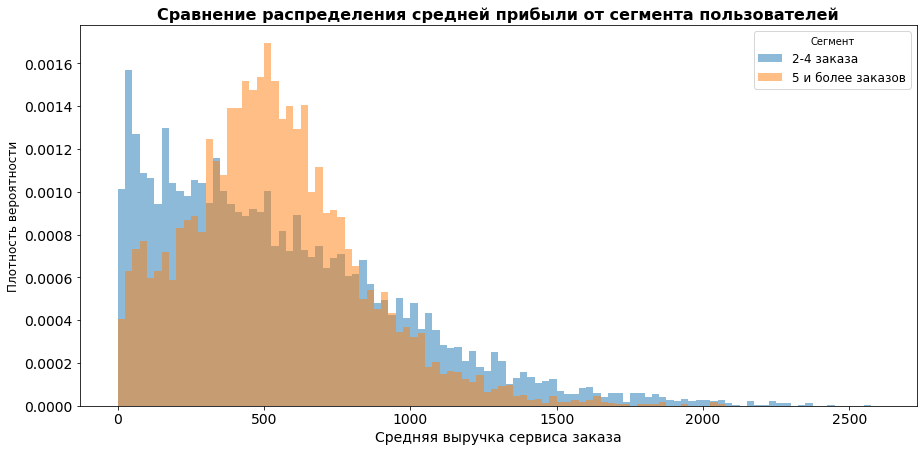

In [61]:

# Выбираем только нужные нам '2-4 заказа' и '5 и более заказов' сегменты
for segment in ('2-4 заказа', '5 и более заказов'):
    # Фильтруем данные по значению столбца segment
    df_temp.loc[df_temp['segment'] == segment, 'mean_revenue'].plot(
        kind='hist',                                           # Тип графика - гистограмма распределения
        density=True,                                          # Задаем значение density как True
        bins=range(0, int(df_temp['mean_revenue'].max()), 25), # Задаем количество интервалов
        alpha=0.5,                                             # Задаем прозрачность alpha
        label=f'{segment}',                                   # Значение подписи на основе сегмента
        legend=True,                                           # Включаем отображение легенды
        fontsize=14,                                           # Устанавливаем размер шрифта
        figsize=(15, 7)                                        # Задаем размер графика
    )

    
# Добавляем подписи к графику с заданными шрифтами
plt.title('Сравнение распределения средней прибыли от сегмента пользователей', fontsize=16, weight='bold')
plt.xlabel('Средняя выручка сервиса заказа', fontsize=14)
plt.ylabel('Плотность вероятности', fontsize=12)
plt.legend(title='Сегмент', fontsize=12)

# Выводим график
plt.show() 

In [62]:
# Рассчитаем среднее и медианное значения средней выручки для каждого сегмента
df_temp.groupby('segment').agg({'mean_revenue':['mean','median']})

mean_revenue            
                          mean      median
segment                                   
1 заказ             544.218933  377.369995
2-4 заказа          550.885193  471.169983
5 и более заказов   534.576355  511.391663

По графику и данным видно, что медианная выручка для пользователей, совершивших 5 и более заказов несколько выше, чем для пользователей, совершивших 2-4 заказа. На графике также видно, что пользователи, совершившие 5 и более заказов чаще имеют среднюю выручку примерно от `250` до `800`, а вот выручку больше `1000` чаще имеют пользователи, совершившие 2-4 заказа.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

    
* С этой задачей тоже справились! 
    
 
* Плюс за грамотное оформление графиков - заголовок, подписи осей, легенда, поправка на размер выборки (`density`). По выводам тоже все верно подмечено!
 

</div>

---

**Задача 4.2.3. Исследование влияния среднего количества билетов в заказе на вероятность повторной покупки.**

Исследуем распределение пользователей по среднему количеству билетов в заказе.

In [63]:
# Изучаем статистические показатели столбца mean_tickets_count
profiles_df['mean_tickets_count'].describe()

count    21628.000000
mean         2.743110
std          0.917881
min          1.000000
25%          2.000000
50%          2.750000
75%          3.100000
max         11.000000
Name: mean_tickets_count, dtype: float64

Медиана среднего количества билетов почти равна среднему - это означает, что выбросов почти нет. `75%` пользователей имеют среднее количество билетов ниже `3.1`

Исследуем распределение среднего количества билетов в заказе для пользователей по сегментам и выясним, как оно влияет на возврат пользователей. Для этого создадим временный датафрейм и разделим пользователей на сегменты по среднему количеству билетов в заказе:
- От 1 до 2 билетов;
- От 2 до 3 билетов;
- От 3 до 5 билетов;
- От 5 и более билетов.

In [64]:
# Разделяем пользователей по сегментам
def split_to_segments(row):
    # Мы знаем, что среднее количество билетов в заказе, как минимум 1.0
    if row['mean_tickets_count'] < 2:
        return 'От 1 до 2 билетов'
    elif row['mean_tickets_count'] < 3:
        return 'От 2 до 3 билетов'
    elif row['mean_tickets_count'] < 5:
        return 'От 3 до 5 билетов'
    else:
        return 'От 5 и более билетов'

# Создаем временный датафрейм на основе исходного, взяв поля 'mean_tickets_count', 'is_two'
temp_df = profiles_df[['mean_tickets_count', 'is_two']].copy()

# Делим пользователей на сегменты, создав новый столбец segment
temp_df['segment'] = temp_df.apply(split_to_segments, axis=1)

# Выводим первые 5 строчек для проверки
temp_df.head(5)

,mean_tickets_count,is_two,segment
1,2.500000,1,От 2 до 3 билетов
5,2.891892,1,От 2 до 3 билетов
6,2.625000,1,От 2 до 3 билетов
9,3.000000,1,От 3 до 5 билетов
11,2.671642,1,От 2 до 3 билетов


In [65]:
# Абсолютное количество пользователей по сегменту среднего количества билетов
print(temp_df['segment'].value_counts())
print()

# Относительное количество пользователей по сегменту среднего количества билетов
print(temp_df['segment'].value_counts(normalize=True))

От 2 до 3 билетов       9492
От 3 до 5 билетов       9054
От 1 до 2 билетов       2421
От 5 и более билетов     661
Name: segment, dtype: int64

От 2 до 3 билетов       0.438876
От 3 до 5 билетов       0.418624
От 1 до 2 билетов       0.111938
От 5 и более билетов    0.030562
Name: segment, dtype: float64


Построим диаграмму размаха для наглядности.

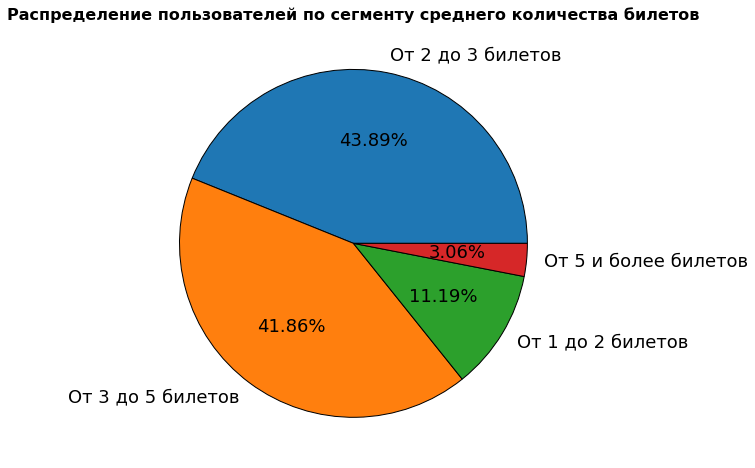

In [66]:
# Строим гистограмму размаха с помощью pandas через .plot.pie
temp_df['segment'].value_counts().plot.pie(
    y='count',                        # Задаем имя колонки для расчетов
    autopct='%1.2f%%',                # Задаем формат подписи долей
    fontsize=18,                      # Задаем размер шрифта подписей на графике
    figsize=(16, 8),                  # Задаем размер графика
    ylabel='',                        # Убираем подпись оси Y
    wedgeprops={'edgecolor': 'black', # Задаем цвет границы
                'linewidth': 1}       # Задаем толщину границы
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение пользователей по сегменту среднего количества билетов', fontsize=16, weight='bold')

# Выводим график
plt.show()

По графику видно, что пользователи распределены концентрированно - есть выраженное доминирование двух сегментов: `От 2 до 3 билетов` и `От 3 до 5 билетов`. То есть `85,75%` всех пользователей имеют от 2 до 5 билетов.

Теперь исследуем, как распределение среднего количества билетов в заказе для пользователей по сегментам влияет на возврат пользователей.

In [67]:
# Группируем пользователей по сегментам среднего количества билетов в заказе
grouped_tickets_segment = temp_df.groupby('segment')['is_two'].agg(
    count='count',        # Сколько пользователей в каждом сегменте
    count_is_two='sum',   # Cколько пользователей имеют 2 и более заказа
    share_is_two='mean'   # Доля пользователей, имеющих 2 и более заказа
).sort_values(by='share_is_two', ascending=False)
grouped_tickets_segment

,count,count_is_two,share_is_two
segment,,,
От 2 до 3 билетов,9492,6982.0,0.735567
От 3 до 5 билетов,9054,4914.0,0.542744
От 1 до 2 билетов,2421,1243.0,0.513424
От 5 и более билетов,661,124.0,0.187595


Построим столбчатую диаграмму для наглядности.

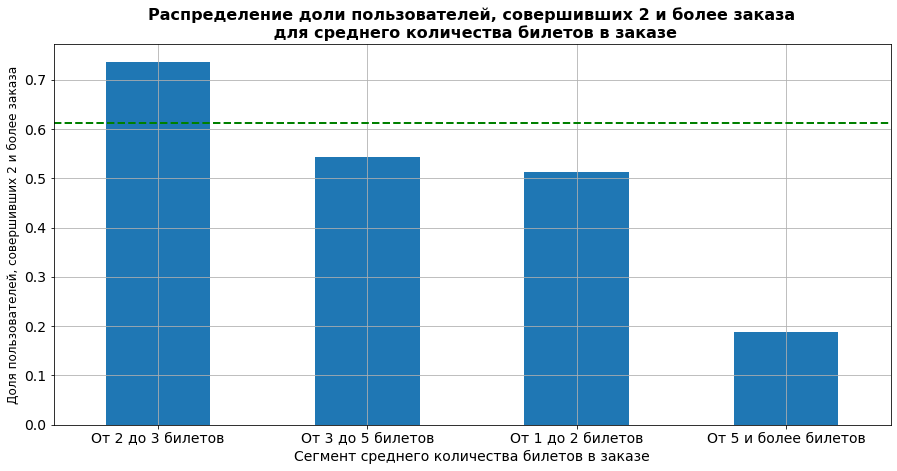

In [68]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
grouped_tickets_segment['share_is_two'].plot(
           kind='bar',     # Тип графика - столбчатая диаграмма
           rot=0,          # Градус вращения подписи по оси Х
           fontsize=14,    # Устанавливаем размер шрифта
           legend=False,   # Выключаем легенду
           figsize=(15, 7) # Задаем размер графика
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение доли пользователей, совершивших 2 и более заказа\n для среднего количества билетов в заказе', fontsize=16, weight='bold')
plt.xlabel('Сегмент среднего количества билетов в заказе', fontsize=14)
plt.ylabel('Доля пользователей, совершивших 2 и более заказа', fontsize=12)

# Рассчитываем долю пользователей, совершивших 2 и более заказа
is_two_share = profiles_df['is_two'].mean()

# Наносим на график линию с долей пользователей, совершивших 2 и более заказа
plt.axhline(is_two_share,   # Данные, по которым строится линия
            color='green',  # Цвет линии
            linestyle='--', # Стиль линии
            linewidth=2     # Ширина линии
)

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show() 

По графику видно, что есть сегменты с высокой и аномально низкой долей повторных покупок - пользователи, имеющие в среднем от 2 до 3 билетов в заказе имеют долю повторной покупки в `73.5%`, а пользователи, имеющие в среднем от 5 и более билетов в заказе имеют долю повторной покупки в `18.7%`.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Можно чуть развить вывод — предположить, почему пользователи, покупающие 2–3 билета, возвращаются чаще. Например, это могут быть небольшие компании или семьи, которые чаще ходят на мероприятия вместе, а значит, лояльность у них выше. А вот пользователи с 5+ билетами, вероятно, совершают разовые групповые покупки (например, для организации или класса), поэтому возвращаются реже

---

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

**Задача 4.3.1. Исследование влияния дня недели первой покупки на поведение пользователей.**

Выделим день недели первой покупки пользователей и для каждого дня недели подсчитаем общее число пользователей и долю пользователей, совершивших повторные заказы. Для этого создадим временный датафрейм и сегментируем по дням недели.

In [69]:
# Создадим соответсвтие для русского названия дня недели
rus_weak_day_names = {
    'Monday':    'Понедельник',
    'Tuesday':   'Вторник',
    'Wednesday': 'Среда',
    'Thursday':  'Четверг',
    'Friday':    'Пятница',
    'Saturday':  'Суббота',
    'Sunday':    'Воскресенье'
}

# Создаем временный датафрейм на основе исходного, взяв поля 'first_date', 'is_two'
temp_df = profiles_df[['first_date', 'is_two']].copy()

# Делим пользователей на сегменты, создав новый столбец first_weak_day
temp_df['first_weak_day'] = temp_df['first_date'].dt.day_name().map(rus_weak_day_names)

# Группируем пользователей по дням недели первого заказа
grouped_first_weak_day = temp_df.groupby('first_weak_day')['is_two'].agg(
    count='count',        # Сколько пользователей в каждом сегменте
    count_is_two='sum',   # Cколько пользователей имеют 2 и более заказа
    share_is_two='mean'   # Доля пользователей, имеющих 2 и более заказа
).sort_values(by='share_is_two', ascending=False)
grouped_first_weak_day

,count,count_is_two,share_is_two
first_weak_day,,,
Понедельник,2930,1847.0,0.630375
Суббота,3325,2088.0,0.627970
Среда,3057,1901.0,0.621851
Вторник,3165,1959.0,0.618957
Воскресенье,2777,1667.0,0.600288
Пятница,3260,1950.0,0.598160
Четверг,3114,1851.0,0.594412


Построим столбчатую диаграмму для наглядности.

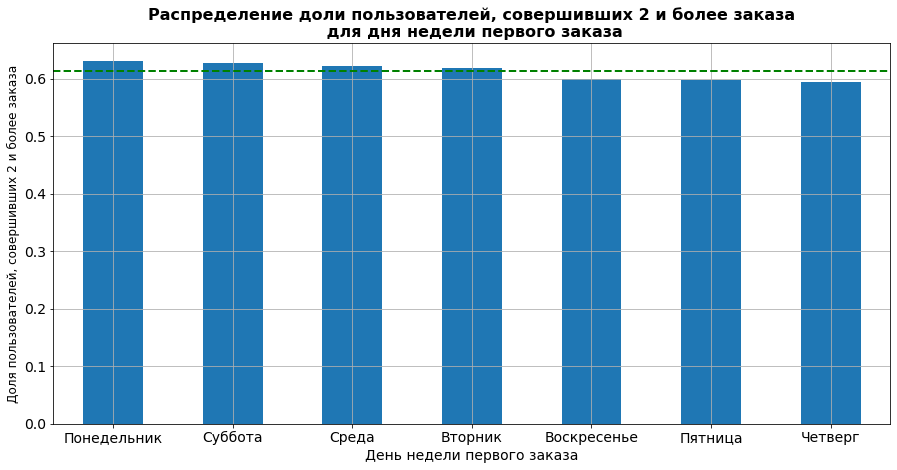

In [70]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
grouped_first_weak_day['share_is_two'].plot(
           kind='bar',     # Тип графика - столбчатая диаграмма
           rot=0,          # Градус вращения подписи по оси Х
           fontsize=14,    # Устанавливаем размер шрифта
           legend=False,   # Выключаем легенду
           figsize=(15, 7) # Задаем размер графика
)

# Добавляем подписи к графику с заданными шрифтами
plt.title('Распределение доли пользователей, совершивших 2 и более заказа\n для дня недели первого заказа', fontsize=16, weight='bold')
plt.xlabel('День недели первого заказа', fontsize=14)
plt.ylabel('Доля пользователей, совершивших 2 и более заказа', fontsize=12)

# Рассчитываем долю пользователей, совершивших 2 и более заказа
is_two_share = profiles_df['is_two'].mean()

# Наносим на график линию с долей пользователей, совершивших 2 и более заказа
plt.axhline(is_two_share,   # Данные, по которым строится линия
            color='green',  # Цвет линии
            linestyle='--', # Стиль линии
            linewidth=2     # Ширина линии
)

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show() 

По данным и графику видно, что влияние дня недели достаточно опосредованно. Хотя при первом дне недели заказа `понедельник` процент возращения равен `63%`, а при `четверг` он составляет `59.4%` - аномального дня недели по проценту возвращения пользователя нет.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Когда планируют досуг, но возвращаемость остаётся примерно одинаковой — это говорит о том, что день недели первой покупки не влияет на лояльность, а повторное использование сервиса определяется скорее качеством опыта и интересом к мероприятиям


**Задача 4.3.2. Исследование вляиния среднего интервала между заказами на удержание клиентов.**


Рассчитаем среднее время между заказами для 2-x групп пользователей:
- Совершивших 2–4 заказа;
- Совершивших 5 и более заказов.

Сначала создадим временный датафрейм, в котором сегментируем пользователей на эти две группы, а затем подсчитаем средний интервал между заказами.

In [71]:
# Разделяем пользователей по сегментам
def split_to_segments(row):
    # is_two == 0 -> 1 заказ (сегмент 1)
    if row['is_two'] == 0:
        return '1 заказ'
    # is_two == 1 and is_five == 0 -> 2-4 заказа (сегмент 2)
    elif row['is_five'] == 0:
        return '2-4 заказа'
    # is_two == 1 and is_five == 1 -> 5+ заказов (сегмент 3)
    else:
        return '5 и более заказов'

# Создаем временный датафрейм на основе исходного, взяв поля 'mean_days_since_prev', 'is_two', 'is_five'
df_temp = profiles_df[['mean_days_since_prev', 'is_two', 'is_five']].copy()

# Делим пользователей на сегменты, создав новый столбец segment
df_temp['segment'] = df_temp.apply(split_to_segments, axis=1)

# Группируем пользователей по сегменту количества заказов и вычисляем средний и медианный интервалы между заказами
df_temp.groupby('segment').agg({'mean_days_since_prev':['mean','median']})

mean_days_since_prev       
                                  mean median
segment                                      
1 заказ                      32.685714    1.0
2-4 заказа                   21.319701    9.0
5 и более заказов              9.91388  8.125

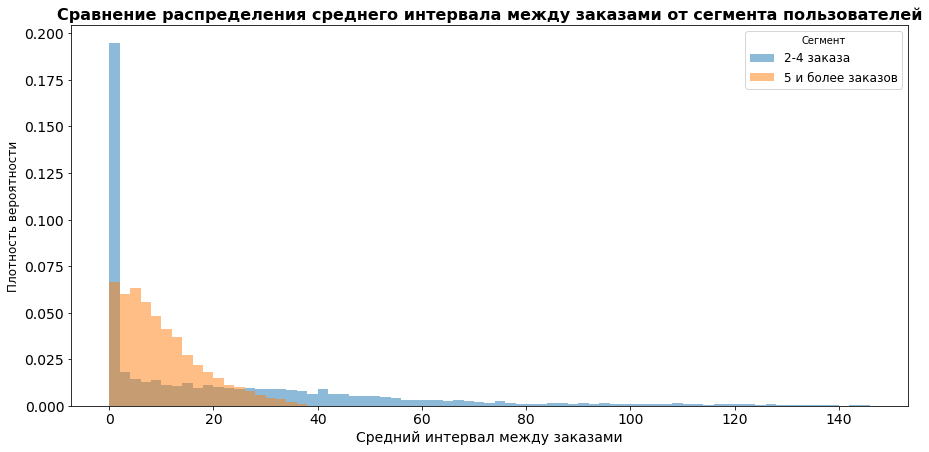

In [72]:
# Выбираем только нужные нам ('2-4 заказа') и ('5 и более заказов') сегменты
for segment in ('2-4 заказа', '5 и более заказов'):
    # Фильтруем данные по значению столбца segment
    df_temp.loc[df_temp['segment'] == segment, 'mean_days_since_prev'].plot(
        kind='hist',                                                  # Тип графика - гистограмма распределения
        density=True,                                                 # Задаем значение density как True
        bins=range(0, int(df_temp['mean_days_since_prev'].max()), 2), # Задаем количество интервалов
        alpha=0.5,                                                    # Задаем прозрачность alpha
        label=f'{segment}',                                           # Значение подписи на основе названия сегмента
        legend=True,                                                  # Включаем отображение легенды
        fontsize=14,                                                  # Устанавливаем размер шрифта
        figsize=(15, 7)                                               # Задаем размер графика
    )

    
# Добавляем подписи к графику с заданными шрифтами
plt.title('Сравнение распределения среднего интервала между заказами от сегмента пользователей', fontsize=16, weight='bold')
plt.xlabel('Средний интервал между заказами', fontsize=14)
plt.ylabel('Плотность вероятности', fontsize=12)
plt.legend(title='Сегмент', fontsize=12)

# Выводим график
plt.show() 

На сегмент пользователей с одним заказом можем не обращать внимание. По данным видно, что медиана у 2-х категория достаточно близка, хотя для сегмента пользователей с 5 и более заказами она ниже. А вот средний интервал времени у двух категорий отличается достаточно сильно. Кроме того, для сегмента с 2-4 заказами медианный интервал сильно ниже среднего. На графике мы видим, что сегмент пользователей с 5 и более заказами по большей части распределен по значениям от `0` до `30` дней, в том время как для сегмента с 5 и более заказами он размазан по всей оси `X`, то есть пользователи в этой категории совершают повторный заказ либо в течении 1 дня, либо не совершают повторный заказ на протяжении долгого времени.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
    
Расчёт абсолютно корректный.    


---

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

---

**Задача 4.4.1. Корреляционный анализ.**

Рассчитаем коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов `total_orders`. Перед построением матрицы корреляции выделим сегменты на основе `total_orders`, поскольку, как мы выяснили в **задаче 3.2**, этот параметр имеет много выбросов справа, то есть много больших значений.
Выделим такие сегменты:
- 1 заказ;
- От 2 до 4 заказов;
- От 5 заказов и выше.

In [73]:
# Разделяем пользователей по сегментам
def split_to_segments(row):
    if row['total_orders'] == 1:
        return '1 заказ'
    elif row['total_orders'] <= 4:
        return 'От 2 до 4 заказов'
    else:
        return 'От 5 заказов и выше'

# Создаем временный датафрейм на основе исходного
corr_df = profiles_df.copy()

# Делим пользователей на сегменты, создав новый столбец total_orders_segment
corr_df['total_orders_segment'] = corr_df.apply(split_to_segments, axis=1)

Изучим кореляцию количества заказов `total_orders_segment` со всеми столбцами, кроме `total_orders`, `is_five`, `is_two`, `user_id`, поскольку `total_orders_segment` был создан на основе `total_orders`, а `is_five` и `is_two` на основе `total_orders`, а `user_id` просто уникальный идентификатор.

In [74]:
exclude = ['total_orders', 'user_id', 'is_five', 'is_two']
necessary_columns = [col for col in corr_df.columns if col not in exclude]

# Вычисляем корреляционную матрицу с использованием phi_k и задаем, какие столбцы интервальные
correlation_matrix = corr_df[necessary_columns].phik_matrix(interval_cols=['mean_revenue', 'mean_tickets_count', 'mean_days_since_prev'])

# Выводим только корреляцию столбца total_orders_segment с остальными данными, исключая сам столбец
correlation_result = correlation_matrix.loc[correlation_matrix.index != 'total_orders_segment'][['total_orders_segment']].sort_values(by='total_orders_segment', ascending=False)
correlation_result

,total_orders_segment
last_date,0.606521
first_date,0.577293
mean_days_since_prev,0.390971
mean_tickets_count,0.383214
mean_revenue,0.327172
first_region_name,0.124701
first_service_name,0.080896
first_event_type_main,0.040350
first_device_type_canonical,0.017204


Визуализируем матрицу корреляции с помощью тепловой карты.

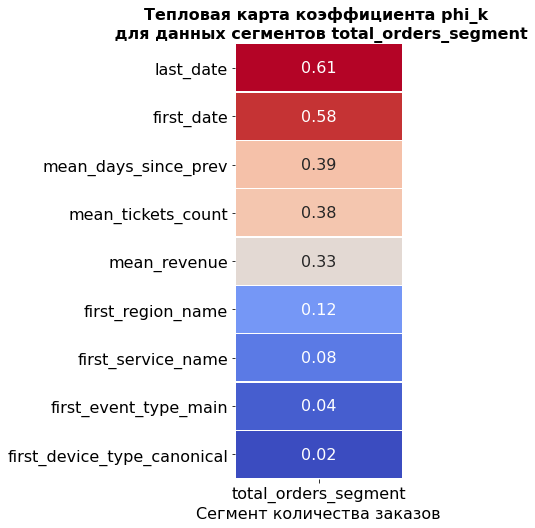

In [75]:
# Задаем размер графика
plt.figure(figsize=(3, 8))

# Строим тепловую карту корреляции признака total_orders_segment с другими признаками пользователей
ax = sns.heatmap(correlation_result,
            annot=True,      # Отображаем численные значения в ячейках карты
            fmt='.2f',       # Форматируем значения корреляции: два знака после точки
            cmap='coolwarm', # Устанавливаем цветовую гамму от красного (макс. значение) к синему
            linewidths=0.5,  # Форматируем линию между ячейками карты
            cbar=False,      # Отключаем цветовую шкалу
            annot_kws={'size': 16} # Размер шрифта аннотации
           )

# Добавляем подписи к графику с заданными шрифтами
ax.tick_params(axis='both', which='major', labelsize=16)
plt.yticks(rotation=0)
plt.title('Тепловая карта коэффициента phi_k \n для данных сегментов total_orders_segment', fontsize=16, weight='bold')
plt.xlabel('Сегмент количества заказов', fontsize=16)

# Выводим график
plt.show()

Наибольшая корреляция наблюдается для столбцов `last_date` и `first_date`. Для столбцов `mean_revenue`, `mean_tickets_count`, `mean_days_since_prev` она также достаточно высока. Корреляция с остальными параметрами уменьшается от `0.12` до `0.02`.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
    
С этим заданием тоже справились!

</div>
<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__

* В выводах Было бы неплохо сделать более явный акцент на том, что поведение клиентов во времени и количество билетов важнее для объяснения повторных покупок, чем их демография или первый выбор сервиса.


<a id="5"></a>
## 5. Общий вывод и рекомендации

### Информация о данных

- Исходный датафрейм содержал `290611` строк и `15` столбцов.
- Данные были хорошего качества - не содержали дубликатов и необоснованных пропусков.
- Данные о выручке были в двух валютах - Российском рубле и Казахстанском тенге. В процессе предобработки данные были приведены к единой валюте - Российскому рублю.
- В ходе предобработки данных были обнаружены аномальные значения в выручке и отфильтрованы по `99` процентилю, в результате чего был удален `1%` данных.
- В ходе работы был создан портрет пользователя на основе первых заказов пользователей. Общее количество заказов имело аномальное значение для некоторых пользователей, в результате чего было принято решение отфильтровать их по `99` процентилю. В результате был удален `1%` данных.

### Основные результаты анализа

- В данных собрана информация о `21628` уникальных пользователях.
- Чаще всего пользователи совершали первый заказ с мобильного телефона - `83%`. Доля возвратов пользователей для компьютера оказалась выше средней `0.638%`.
- Возврат пользователей был выше, если первым типом их мероприятия были концерты и выставки, а для спортивных мероприятий и ёлок ниже среднего.
- Количество мероприятий в регионе не влияет на вероятность возвращения пользователей. `Шанырский регион` имеет рейтинг возврата `67.2%`, хотя имеет `500` первых заказов суммарно. Около `70` регионов имеют долю повторного заказа существенно ниже средней.
- Пользователи совершившие 2 и более заказа имеют бОльшую медианную прибыль с заказа.
- Пользователи, имеющие в среднем от 2 до 3 билетов в заказе имеют долю повторной покупки в `73.5%`, а пользователи, имеющие в среднем от 5 и более билетов в заказе имеют долю повторной покупки в `18.7%`. При этом `85,75%` всех пользователей имеют от 2 до 5 билетов в заказе
- При первом дне недели заказа `понедельник` процент возращения пользователя равен `63%`, а при `четверге` он составляет `59.4%`.
- Медианный интервал между заказами почти не зависит от их количества.
- Наибольшая корреляция количества заказов наблюдается для даты первого и последнего заказа. Для средней выручки, среднего количества билетов она также достаточно высока.

### Рекомендации на основе анализа данных

Для повышения процента возврата пользователей рекомендуется обратить внимание на регион проведения мероприятия. В определенных регионах он существенно выше остальных. Билетные операторы `Край билетов` и `Дом культуры` имеют более высокий процент возврата пользователей. Особое внимание стоит обратить на тип мероприятия - концерты и выставки показывают больший процент возврата пользователей. Спортивные мероприятия и ёлки требуют дополнительных условий для повышения вероятности возврата пользователей. В качестве дня проведения мероприятия рекомендуется выбрать понедельник. Возможно стоит добавить скидки для пользователей, покупающих 5 и более билетов сразу, то есть на компанию, поскольку вероятность их возврата крайне низкая. 

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__
    
С задачей справились! Все ключевые моменты отражены, что позволяет быстро ознакомиться с процессом работы и результатом, не вдаваясь в технический детали. Здорово, что завершаешь проект рекомендациями, основанные на выявленных закономерностях. Предложенные рекомендации логично следуют из анализа и могут быть непосредственно реализованы в маркетинговых стратегиях подогревания и удержания. 

</div>

## 6. Финализация проекта и публикация в Git


**https://github.com/justASimpleUser2/YandexAfisha**

<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__


    

Сейчас ты явным образом прописываешь параметры подключения к БД. В таком виде выкладывать работу в публичный доступ небезопасно, кто-то сможет завладеть подключением, украсть или повредить данные. 
    
Чтобы засекретить подключение, необходимо сложить все параметры в `.env` файл (или другой конфигурационный файл вне Git) и указать его в `.gitignore`:

```python
DB_NAME="..."
DB_HOST="..."
DB_PORT="..."
DB_USER="..."
DB_PASSWORD="..."
```
    
